# 01 — Data, Model & Training

Build a synthetic binary dataset, define the MLP, verify the forward and backward
passes by hand, then train with full-batch gradient descent and watch every number
that matters.

**Run all cells top-to-bottom.** "Restart Kernel and Run All" must pass.

> **Kernel:** `source /root/LLM/venv/bin/activate && jupyter notebook --notebook-dir=neural_nets/notebooks`

**What we do:** Import libraries and set every constant that controls the notebook.
**Why:** One place to change a value — no hunting through cells.
**What you should see:** No output.

| Constant | Value | Meaning |
|---|---|---|
| `FORCE_CPU` | `False` | Set `True` to skip the GPU and run entirely on CPU |
| `SEED` | `42` | Fixed integer passed to PyTorch and NumPy so every random draw is reproducible |
| `LAYER_SIZES` | `[3, 3, 2, 1]` | Neuron count per layer: 3 inputs → hidden layer of 3 → hidden layer of 2 → 1 output |
| `EPOCHS` | `300` | Number of full passes through the training set |
| `LR` | `0.1` | Learning rate — how large each gradient step is: `W ← W − LR · ∇W` |
| `LOG_EVERY` | `30` | Print diagnostics every 30 epochs (reduces output while still showing progress) |
| `SNAP_AT` | `{0,100,200,300}` | Epochs at which to save a full copy of all weight matrices for the heatmap comparison |

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import json, pathlib
import matplotlib.pyplot as plt

# ── configuration ─────────────────────────────────────────────────────────────
FORCE_CPU   = False
SEED        = 42
LAYER_SIZES = [3, 3, 2, 1]   # input → hidden1 → hidden2 → output
EPOCHS      = 300
LR          = 0.1
LOG_EVERY   = 30
SNAP_AT     = {0, 100, 200, 300}
# ─────────────────────────────────────────────────────────────────────────────

torch.manual_seed(SEED)
np.random.seed(SEED)

**What we do:** Detect the compute device and set up the artifacts directory.
**Why:** One device flag (`FORCE_CPU`) controls the whole notebook end-to-end.
**What you should see:** Device and artifacts path.

In [2]:
NOTEBOOK_DIR  = pathlib.Path().resolve()
ARTIFACTS_DIR = NOTEBOOK_DIR.parent / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

if FORCE_CPU:
    device = torch.device("cpu")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"GPU : {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")

print(f"device        : {device}")
print(f"artifacts dir : {ARTIFACTS_DIR}")

GPU : NVIDIA GeForce RTX 2050
device        : cuda
artifacts dir : /root/LLM/neural_nets/artifacts


**What we do:** Generate 1000 samples (3 features from N(0,1)) with a non-linear
saddle-surface boundary, then flip 5% of labels at random.
**Why:** The boundary `x1² − x2² + x3 > 0` is not linearly separable — the network
must learn a curved decision surface. Label noise prevents memorisation.
**What you should see:** Class balance ≈ 50/50 and the noise count.

---

**Understanding the boundary `x1² − x2² + x3 > 0` piece by piece:**

| Term | Shape | Effect |
|------|-------|--------|
| `x1²` | parabola opening up (≥ 0) | increases the score when x1 is large in either direction |
| `−x2²` | parabola opening down (≤ 0) | decreases the score when x2 is large in either direction |
| `x1² − x2²` | **saddle surface** | positive along the x1-axis, negative along the x2-axis |
| `+ x3` | linear tilt | a large positive x3 can flip a negative saddle value to positive; a large negative x3 flips it back |

**Why this is hard for a linear model:** A hyperplane `w1·x1 + w2·x2 + w3·x3 > b` can never reproduce a squared term — it would need to treat x1=+2 and x1=−2 the same (both give x1²=4), but a linear model cannot do that. The MLP must learn the squaring behaviour from the data.

In [3]:
torch.manual_seed(SEED)
np.random.seed(SEED)

N = 1000
X = torch.randn(N, 3)

logit_clean = X[:, 0]**2 - X[:, 1]**2 + X[:, 2] 
y_clean     = (logit_clean > 0).long()

flip = torch.bernoulli(torch.full((N,), 0.05)).bool()
y    = y_clean.clone()
y[flip] = 1 - y[flip]

pos = y.sum().item()
print(f"N={N},  features=3,  boundary: x1² - x2² + x3 > 0")
print(f"Class balance : {pos} pos ({100*pos/N:.1f}%)  {N-pos} neg ({100*(N-pos)/N:.1f}%)")
print(f"Noisy labels  : {flip.sum().item()} flipped ({100*flip.float().mean():.1f}%)")

assert y.shape == (N,)
assert set(y.unique().tolist()) == {0, 1}
print("\nPASS: dataset created")

N=1000,  features=3,  boundary: x1² - x2² + x3 > 0
Class balance : 524 pos (52.4%)  476 neg (47.6%)
Noisy labels  : 36 flipped (3.6%)

PASS: dataset created


**What we do:** Visualise the boundary in three steps — x1² alone, x2² alone,
the saddle x1²−x2², then the full equation with the x3 tilt — using 2D curves,
contour maps, and a 3D surface.
**Why:** Plotting each term separately shows exactly what role it plays before
combining them. The 3D surface makes the saddle shape unmistakable.
**What you should see:** Four panels building up the boundary, then a scatter of
the 1000 data points coloured by class.

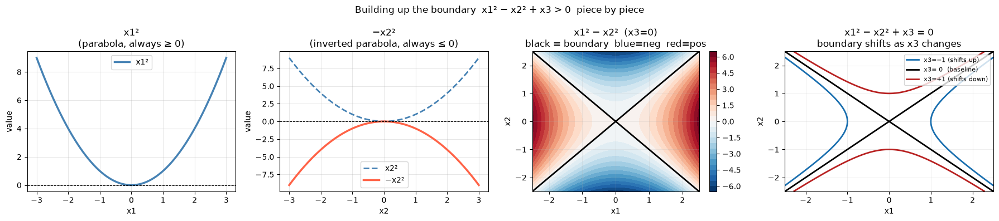

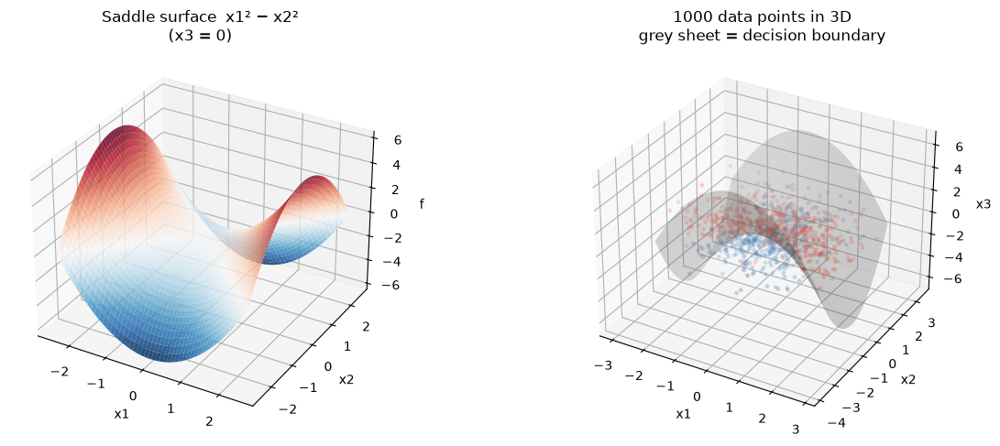

In [4]:
from mpl_toolkits.mplot3d import Axes3D   # registers the 3D projection

t  = np.linspace(-3, 3, 300)             # 1-D sweep
g  = np.linspace(-2.5, 2.5, 150)        # 2-D grid axis
G1, G2 = np.meshgrid(g, g)

# ── Panel row 1: build up the equation term by term ──────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# 1. x1² — a parabola
axes[0].plot(t, t**2, color="steelblue", lw=2.5, label="x1²")
axes[0].axhline(0, color="k", lw=0.8, linestyle="--")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("value")
axes[0].set_title("x1²\n(parabola, always ≥ 0)")
axes[0].legend(); axes[0].grid(alpha=0.3)

# 2. −x2² — an inverted parabola
axes[1].plot(t, t**2,  color="steelblue", lw=2, linestyle="--", label="x2²")
axes[1].plot(t, -t**2, color="tomato",    lw=2.5, label="−x2²")
axes[1].axhline(0, color="k", lw=0.8, linestyle="--")
axes[1].set_xlabel("x2"); axes[1].set_ylabel("value")
axes[1].set_title("−x2²\n(inverted parabola, always ≤ 0)")
axes[1].legend(); axes[1].grid(alpha=0.3)

# 3. Saddle x1² − x2² (x3 = 0) — contour map
Z_saddle = G1**2 - G2**2
cf = axes[2].contourf(G1, G2, Z_saddle, levels=30, cmap="RdBu_r")
axes[2].contour(G1, G2, Z_saddle, levels=[0], colors="k", linewidths=2)
plt.colorbar(cf, ax=axes[2])
axes[2].set_xlabel("x1"); axes[2].set_ylabel("x2")
axes[2].set_title("x1² − x2²  (x3=0)\nblack = boundary  blue=neg  red=pos")
axes[2].grid(alpha=0.2)

# 4. Full equation with x3 shift — show x3=−1, 0, +1
for x3_val, col, lbl in [(-1,"#1a6faf","x3=−1"), (0,"k","x3=0"), (1,"#b82121","x3=+1")]:
    Z_full = G1**2 - G2**2 + x3_val
    axes[3].contour(G1, G2, Z_full, levels=[0], colors=col, linewidths=2)
axes[3].set_xlabel("x1"); axes[3].set_ylabel("x2")
axes[3].set_title("x1² − x2² + x3 = 0\nboundary shifts as x3 changes")
axes[3].legend(handles=[
    plt.Line2D([],[],color="#1a6faf",lw=2,label="x3=−1 (shifts up)"),
    plt.Line2D([],[],color="k",     lw=2,label="x3= 0  (baseline)"),
    plt.Line2D([],[],color="#b82121",lw=2,label="x3=+1 (shifts down)"),
], fontsize=8)
axes[3].grid(alpha=0.2)

fig.suptitle("Building up the boundary  x1² − x2² + x3 > 0  piece by piece", fontsize=12)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "boundary_buildup.png", dpi=110, bbox_inches="tight")
plt.show()

# ── 3D surface: the full saddle ───────────────────────────────────────────────
fig3d = plt.figure(figsize=(13, 5))

ax_l = fig3d.add_subplot(121, projection="3d")
ax_l.plot_surface(G1, G2, G1**2 - G2**2,
                  cmap="RdBu_r", alpha=0.85, linewidth=0)
ax_l.set_xlabel("x1"); ax_l.set_ylabel("x2"); ax_l.set_zlabel("f")
ax_l.set_title("Saddle surface  x1² − x2²\n(x3 = 0)")

ax_r = fig3d.add_subplot(122, projection="3d")
X_np_plot = X.numpy()
y_np_plot  = y.numpy()
colors_pts = ["tomato" if yi == 1 else "steelblue" for yi in y_np_plot]
ax_r.scatter(X_np_plot[:, 0], X_np_plot[:, 1], X_np_plot[:, 2],
             c=colors_pts, s=6, alpha=0.5)
# draw the boundary surface (f = 0  →  x3 = x2² − x1²)
ax_r.plot_surface(G1, G2, G2**2 - G1**2,
                  alpha=0.25, color="gray", linewidth=0)
ax_r.set_xlabel("x1"); ax_r.set_ylabel("x2"); ax_r.set_zlabel("x3")
ax_r.set_title("1000 data points in 3D\ngrey sheet = decision boundary")

fig3d.tight_layout()
fig3d.savefig(ARTIFACTS_DIR / "boundary_3d.png", dpi=110, bbox_inches="tight")
plt.show()

**What we do:** Shuffle with a fixed seed, hold out 200 samples as the test set,
save them to `artifacts/test_set.npz`.
**Why:** Committing the test set to disk before any modelling choice ensures it
cannot influence architecture or hyperparameter decisions.
**What you should see:** Split sizes and PASS confirming no overlap.

In [5]:
X_np = X.numpy()
y_np = y.numpy()

rng = np.random.default_rng(SEED)
idx = rng.permutation(N)

n_test, n_val, n_train = 200, 160, 640   # 20% / 16% / 64%

idx_train = idx[:n_train]
idx_val   = idx[n_train:n_train + n_val]
idx_test  = idx[n_train + n_val:]

X_test_raw, y_test = X_np[idx_test], y_np[idx_test]
np.savez(ARTIFACTS_DIR / "test_set.npz", X=X_test_raw, y=y_test)

print(f"train={n_train}  val={n_val}  test={n_test}")
print(f"Test label balance : {y_test.mean():.3f}  (ideal 0.500)")
print(f"Saved : artifacts/test_set.npz  (raw, untouched until notebook 02)")

assert len(np.intersect1d(idx_train, idx_test)) == 0, "FAIL: train/test overlap"
assert len(np.intersect1d(idx_val,   idx_test)) == 0, "FAIL: val/test overlap"
assert len(np.intersect1d(idx_train, idx_val))  == 0, "FAIL: train/val overlap"
print("\nPASS: splits are disjoint")

train=640  val=160  test=200
Test label balance : 0.525  (ideal 0.500)
Saved : artifacts/test_set.npz  (raw, untouched until notebook 02)

PASS: splits are disjoint


**What we do:** Fit the standardizer on training data only, apply it to train and val.
**Why:** Using training mean and std prevents any information from val or test rows
leaking into the model's input scale.
**What you should see:** Training mean ≈ 0 and std ≈ 1 per feature after scaling.

In [6]:
X_train_raw = X_np[idx_train]
X_val_raw   = X_np[idx_val]
y_train     = y_np[idx_train]
y_val       = y_np[idx_val]

mu  = X_train_raw.mean(axis=0)   # fit on train only
sig = X_train_raw.std(axis=0)

X_train = (X_train_raw - mu) / sig
X_val   = (X_val_raw   - mu) / sig

print(f"Training mu  : {mu.round(4)}")
print(f"Training sig : {sig.round(4)}")
print(f"X_train mean : {X_train.mean(axis=0).round(4)}")
print(f"X_train std  : {X_train.std(axis=0).round(4)}")

assert abs(X_train.mean()) < 1e-6,      "FAIL: training mean not zero"
assert abs(X_train.std() - 1.0) < 0.05, "FAIL: training std not near 1"
print("\nPASS: standardization correct")

Training mu  : [ 0.0348  0.0039 -0.0063]
Training sig : [1.0294 1.0165 0.966 ]
X_train mean : [ 0. -0. -0.]
X_train std  : [1. 1. 1.]

PASS: standardization correct


**What we do:** Save standardized train/val arrays, scaler params, and config
to `artifacts/` so notebook 02 can load them.
**Why:** Notebooks share state only through files — no cross-notebook imports.
**What you should see:** Four filenames confirmed.

In [7]:
np.savez(ARTIFACTS_DIR / "train_val.npz",
         X_train=X_train, y_train=y_train,
         X_val=X_val,     y_val=y_val)

scaler = {"mean": mu.tolist(), "std": sig.tolist()}
with open(ARTIFACTS_DIR / "scaler.json", "w") as f:
    json.dump(scaler, f, indent=2)

config = {
    "N": N, "n_train": n_train, "n_val": n_val, "n_test": n_test,
    "layer_sizes": LAYER_SIZES, "seed": SEED, "noise_rate": 0.05,
}
with open(ARTIFACTS_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print(f"train_val.npz : X_train {X_train.shape}  X_val {X_val.shape}")
print(f"test_set.npz  : X_test_raw {X_test_raw.shape}  (raw, not standardized)")
print(f"scaler.json   : mu={mu.round(3).tolist()}")
print(f"config.json   : {config}")
print("\nPASS: all artifacts saved")

train_val.npz : X_train (640, 3)  X_val (160, 3)
test_set.npz  : X_test_raw (200, 3)  (raw, not standardized)
scaler.json   : mu=[0.03500000014901161, 0.004000000189989805, -0.006000000052154064]
config.json   : {'N': 1000, 'n_train': 640, 'n_val': 160, 'n_test': 200, 'layer_sizes': [3, 3, 2, 1], 'seed': 42, 'noise_rate': 0.05}

PASS: all artifacts saved


**What we do:** Define the `MLP` class with explicit `nn.Tanh` / `nn.Sigmoid`
activation modules (not inline function calls).
**Why:** PyTorch hooks attach to `nn.Module` objects — not to plain functions. By
storing each activation as a separate `nn.Module` in `self.acts`, we can later call
`act.register_forward_hook(fn)` on each one and capture z(l) automatically after
every forward pass, without touching `forward()`.
**What you should see:** No output.

**Hooks we will attach (registered in the hooks cell below):**

| Hook | Attached to | Captures | Why we need it |
|------|-------------|----------|----------------|
| `register_forward_hook` | each `nn.Tanh` / `nn.Sigmoid` in `self.acts` | `z(l)` — post-activation output | **Diagnose training health:** if the z(l) values of a tanh layer cluster near ±1, those neurons are saturated: the derivative 1 − z² is close to 0, so almost no gradient flows through them. `act_std` shows whether the outputs of a layer still differ from each other; `sat_frac` measures the fraction of saturated neurons. Without hooks we'd have to rewrite `forward()` every time we want to inspect internals. |

The hook fires automatically on every `model(x)` call and stores the result in `_act_store[l]`, keyed by layer index. After training completes the store holds the final z(l) for each layer on the last batch seen.

In [8]:
class MLP(nn.Module):
    def __init__(self, sizes):
        super().__init__()
        self.layers = nn.ModuleList([
            nn.Linear(sizes[i], sizes[i + 1])
            for i in range(len(sizes) - 1)
        ])
        self.acts = nn.ModuleList(
            [nn.Tanh() for _ in range(len(sizes) - 2)] + [nn.Sigmoid()]
        )

    def forward(self, x):
        z = x
        for linear, act in zip(self.layers, self.acts):
            z = act(linear(z))   # a(l) = linear(z);  z(l) = act(a(l))
        return z

**What we do:** Instantiate the network and print W(l) shapes.
**Why:** Verifying shapes before any computation catches dimension mismatches early.
**What you should see:** Three layers with W(l) shapes matching the diagram, total
parameters = 23.

---

**How the matrix dimensions chain together** (`LAYER_SIZES = [3, 3, 2, 1]`):

Rule: **W(l) shape = (neurons_l × neurons_{l-1})** — rows = neurons going out, columns = inputs coming in.

```
z(0) = x           shape (3,1)   ← 3 input features

W(1)               shape (3×3)   ← 3 neurons, each with 3 weights (one per input)
a(1) = W(1)·z(0)   (3×3)·(3×1) = (3×1)  ✓   inner dims both 3
z(1) = tanh(a(1))  shape (3,1)

W(2)               shape (2×3)   ← 2 neurons, each with 3 weights (one per z(1))
a(2) = W(2)·z(1)   (2×3)·(3×1) = (2×1)  ✓   inner dims both 3
z(2) = tanh(a(2))  shape (2,1)

W(3)               shape (1×2)   ← 1 neuron,  each with 2 weights (one per z(2))
a(3) = W(3)·z(2)   (1×2)·(2×1) = (1×1)  ✓   inner dims both 2
z(3) = σ(a(3))     scalar
```

Each row of W(l) is the weight vector for one neuron. The inner dimensions always cancel — that is what makes the multiplication valid at every layer.

In [9]:
torch.manual_seed(SEED)
model = MLP(LAYER_SIZES)   # CPU for now; moved to device before training

total = sum(p.numel() for p in model.parameters())
print(f"Architecture : {' -> '.join(str(s) for s in LAYER_SIZES)}")
print(f"Activations  : tanh / tanh / sigmoid")
print()
for l, layer in enumerate(model.layers, 1):
    print(f"  Layer {l}:  W({l}) {tuple(layer.weight.shape)}  b({l}) {tuple(layer.bias.shape)}")
print()
print(f"Total parameters: {total}")

expected = sum(LAYER_SIZES[i]*LAYER_SIZES[i+1] + LAYER_SIZES[i+1]
               for i in range(len(LAYER_SIZES)-1))
assert total == expected, f"FAIL: expected {expected} params, got {total}"
print("PASS: parameter count correct")

Architecture : 3 -> 3 -> 2 -> 1
Activations  : tanh / tanh / sigmoid

  Layer 1:  W(1) (3, 3)  b(1) (3,)
  Layer 2:  W(2) (2, 3)  b(2) (2,)
  Layer 3:  W(3) (1, 2)  b(3) (1,)

Total parameters: 23
PASS: parameter count correct


**What we do:** Play the forward pass as an animation that uses only symbols — no numbers. It follows the *Backpropagation Deep Dive* notes.
**Why:** The shapes printed above (W(1) 3×3, W(2) 2×3, W(3) 1×2) all come from one rule. The animation shows where it comes from: one equation per neuron stacks into one matrix equation, layer by layer.
**What you should see:** One video (~75 s), then a PASS.

| Part of the video | What it shows |
|---|---|
| Reading the picture | each neuron split into `a` (weighted sum + b) and `z = h(a)`; 17 weights + 6 biases = 23 numbers |
| The numbering rule | `w₂₃⁽¹⁾`: bracket = layer, first index = destination neuron, second index = source |
| Layer 1 | three scalar equations (one per neuron) factored into `a = W·x + b`, row j of W = weights into neuron j |
| Layers 2 and 3 | the same recipe on `z(1)` and `z(2)`; W has one row per neuron here and one column per neuron before |
| Whole network | one nested formula, and the three-line program with shapes (3×1), (2×1), (1×1) |

Scene source: `tools/manim/forward_pass.py`. Re-render: `manim -r 1280,720 --fps 15 tools/manim/forward_pass.py ForwardPass`, then copy the mp4 into `artifacts/manim/`.

In [10]:
from IPython.display import Video, display

path = ARTIFACTS_DIR / "manim" / "ForwardPass.mp4"
assert path.exists(), "FAIL: ForwardPass.mp4 missing — run: manim -r 1280,720 --fps 15 tools/manim/forward_pass.py ForwardPass"
display(Video(str(path), embed=True, width=800))
print("PASS: forward-pass animation found")

PASS: forward-pass animation found


**What we do:** Pick one training sample and compute the forward pass by hand —
a matrix-vector product at each layer — printing every intermediate value.
**Why:** Seeing the actual numbers at each step (a(l) and z(l)) makes the
computation concrete before any weight is updated.
**What you should see:** a(l) and z(l) for layers 1–3, then the raw prediction.

In [11]:
model.eval()
x_s = torch.tensor(X_train[0], dtype=torch.float32)   # shape (3,)
y_s = float(y_train[0])
print(f"Sample 0:  x = {x_s.numpy().round(4)},  y = {int(y_s)}")
print()

W1, b1 = model.layers[0].weight.data, model.layers[0].bias.data
W2, b2 = model.layers[1].weight.data, model.layers[1].bias.data
W3, b3 = model.layers[2].weight.data, model.layers[2].bias.data

a1 = W1 @ x_s + b1;  z1 = torch.tanh(a1)
print(f"Layer 1:  a(1) = {a1.detach().numpy().round(4)}")
print(f"          z(1) = tanh(a(1)) = {z1.detach().numpy().round(4)}")

a2 = W2 @ z1 + b2;   z2 = torch.tanh(a2)
print(f"Layer 2:  a(2) = {a2.detach().numpy().round(4)}")
print(f"          z(2) = tanh(a(2)) = {z2.detach().numpy().round(4)}")

a3 = W3 @ z2 + b3;   z3 = torch.sigmoid(a3)
print(f"Layer 3:  a(3) = {a3.detach().numpy().round(4)}")
print(f"          z(3) = sigmoid(a(3)) = {z3.detach().numpy().round(4)}")
print(f"\nHand prediction: {z3.item():.8f}")

Sample 0:  x = [ 0.5348  0.7438 -1.0427],  y = 0

Layer 1:  a(1) = [ 0.31    0.5699 -0.3208]
          z(1) = tanh(a(1)) = [ 0.3005  0.5153 -0.3102]
Layer 2:  a(2) = [-0.1874  0.3255]
          z(2) = tanh(a(2)) = [-0.1853  0.3145]
Layer 3:  a(3) = [-0.2529]
          z(3) = sigmoid(a(3)) = [0.4371]

Hand prediction: 0.43710566


**What we do:** Pass the same sample through `model.forward()` and compare
with the hand result.
**Why:** Agreement proves the hand computation is correct — we can trust it
for the backward pass too.
**What you should see:** Two identical values and PASS.

In [12]:
with torch.no_grad():
    module_out = model(x_s.unsqueeze(0)).item()

diff = abs(z3.item() - module_out)
print(f"Module prediction : {module_out:.8f}")
print(f"Hand   prediction : {z3.item():.8f}")
print(f"Difference        : {diff:.2e}")

assert diff < 1e-5, f"FAIL: forward mismatch {diff:.2e}"
print("\nPASS: hand forward pass matches module")

Module prediction : 0.43710566
Hand   prediction : 0.43710566
Difference        : 0.00e+00

PASS: hand forward pass matches module


---

## Backpropagation — the plain idea

**What is it?**
After a forward pass we know how wrong the prediction was (the loss). Backpropagation answers the question: *how much did each weight contribute to that error?* It does this by propagating the error signal backward, from the output toward the inputs, and computing the gradient ∂E/∂w of every weight.

**The intuition in three sentences:**
1. The output is wrong by some amount. That amount is the starting error signal.
2. Each layer passes the error signal backward through its own weights, scaling it by how sensitive the layer's output was to a change in input (the activation derivative).
3. The gradient for a weight is the product of the error signal that arrived at that layer and the input that weight acted on. A weight whose input is large *and* whose neuron has a large error signal gets the largest gradient.

**Why the transpose `W(l)ᵀ`?**
During the forward pass, W(l) maps inputs → outputs (left to right).
During the backward pass, we need to map error signals back from outputs → inputs (right to left).
Transposing the matrix is exactly the operation that reverses that direction.

**Why the activation derivative `(1 - z²)` for tanh?**
For a large input, tanh is saturated (the output is near ±1 and the curve is nearly flat), so a small change of the input barely changes the output. The derivative 1 − z² measures this. Multiplying by it means: *if the activation is saturated, almost none of the error signal passes through.*

**Summary of the backward pass (three layers, our network):**
```
Start at output:    δ(3) = prediction − label                      (sigmoid + BCE)
Layer 3 → 2:       δ(2) = (W(3)ᵀ δ(3)) ⊙ (1 − z(2)²)
Layer 2 → 1:       δ(1) = (W(2)ᵀ δ(2)) ⊙ (1 − z(1)²)
Each layer:         gradient for W(l) = δ(l) ⊗ z(l-1)
                    gradient for b(l) = δ(l)
```

The math below makes each of these steps exact.

---

**What we do:** Play backpropagation as an animation that uses only symbols — no numbers. It follows the *Backpropagation Deep Dive* notes.
**Why:** The plain-idea section above says *what* backprop does; this shows *why each formula looks the way it does*, one link of the chain at a time, before the exact derivation and the hand-computed gradients below.
**What you should see:** One video (~3 min), then a PASS. Stages 1–5 are slow on purpose: every formula is derived line by line, with the reason for each step.

| Part of the video | What it shows |
|---|---|
| Three tools | slope, the chain rule (slopes multiply), and one value with two routes (add them) |
| Stages 1–5 | the path `w → a → z → a(3) → y → E` lit up on the network, one link at a time, each slope derived: power rule for `y − t`; quotient simplifying to `y(1 − y)` for the sigmoid; treating the other terms as constants for `w`; quotient rule giving `1 − z²` for tanh; why the derivative with respect to a weight is the layer input z |
| Stages 6–7 | one layer further back: `z(1)` feeds both layer-2 neurons, so the two paths are added |
| One rule for every layer | Move A (start at the output; MSE vs our BCE), Move B (gradient = δ × the layer input z), Move C (pass δ back) |
| Matrix form | `δ(l) = (W(l+1)ᵀ δ(l+1)) ⊙ h′(a(l))`, column of W becomes row of Wᵀ, gradient as an outer product |
| Six lines | the whole sweep as the code in the hand-gradient cell below, then the update step |

Scene source: `tools/manim/backward_pass.py`. Re-render: `manim -r 1280,720 --fps 15 tools/manim/backward_pass.py BackwardPass`, then copy the mp4 into `artifacts/manim/`.

In [13]:
from IPython.display import Video, display

path = ARTIFACTS_DIR / "manim" / "BackwardPass.mp4"
assert path.exists(), "FAIL: BackwardPass.mp4 missing — run: manim -r 1280,720 --fps 15 tools/manim/backward_pass.py BackwardPass"
display(Video(str(path), embed=True, width=800))
print("PASS: backward-pass animation found")

PASS: backward-pass animation found


**What we do:** Compute all gradients by hand using the delta rules.
**Why:** Walking through each delta makes the chain rule concrete and shows
exactly how the error signal flows backward through the network.
**What you should see:** Three delta vectors and six gradient tensors.

---

**Backpropagation — where every formula comes from:**

**Step 0 — the loss** (BCE with sigmoid output):
```
E = -[ y·log(z(3)) + (1-y)·log(1-z(3)) ]
```

**Step 1 — output delta** `delta(3) = dE/da(3)`

Apply chain rule:  `dE/da(3) = dE/dz(3) · dz(3)/da(3)`

- `dE/dz(3)  = -y/z(3) + (1-y)/(1-z(3))`   ← derivative of BCE loss
- `dz(3)/da(3) = z(3)·(1-z(3))`               ← derivative of sigmoid

These multiply to a clean form (the two cancel):
```
delta(3) = z(3) - y          ← prediction minus true label
```

**Step 2 — hidden deltas** `delta(l) = dE/da(l)`

The error at layer l is the error from the layer above, propagated back through W and squeezed by the activation derivative:
```
delta(2) = W(3)ᵀ · delta(3)  ⊙  (1 - z(2)²)     ← tanh'(a) = 1 - tanh(a)²
delta(1) = W(2)ᵀ · delta(2)  ⊙  (1 - z(1)²)
```
`⊙` = element-wise multiply. `W(l)ᵀ` routes the error back through the transpose of the weight matrix.

**Step 3 — weight and bias gradients**
```
dE/dW(l) = delta(l) ⊗ z(l-1)ᵀ    ← outer product: ∂E/∂w_kj = δ_k · z_j
dE/db(l) = delta(l)                ← the bias multiplies the constant 1, so its gradient is δ
```

**Update rule** (gradient descent, applied by the optimizer):
```
W(l) ← W(l) - lr · dE/dW(l)
b(l) ← b(l) - lr · dE/db(l)
```

---

In [14]:
delta3 = z3.detach() - y_s
delta2 = (W3.T @ delta3) * (1.0 - z2.detach()**2)
delta1 = (W2.T @ delta2) * (1.0 - z1.detach()**2)

dW3 = delta3.unsqueeze(1) @ z2.detach().unsqueeze(0)
db3 = delta3
dW2 = delta2.unsqueeze(1) @ z1.detach().unsqueeze(0)
db2 = delta2
dW1 = delta1.unsqueeze(1) @ x_s.unsqueeze(0)
db1 = delta1

print(f"delta(3) = z(3)-y            : {delta3.numpy().round(6)}")
print(f"delta(2) = W3T·d3 * (1-z2²) : {delta2.numpy().round(6)}")
print(f"delta(1) = W2T·d2 * (1-z1²) : {delta1.numpy().round(6)}")
print(f"\ndW(3) = {dW3.numpy().round(6)}")
print(f"db(3) = {db3.numpy().round(6)}")
print(f"dW(2) =\n{dW2.numpy().round(6)}")
print(f"db(2) = {db2.numpy().round(6)}")
print(f"dW(1) =\n{dW1.numpy().round(6)}")
print(f"db(1) = {db1.numpy().round(6)}")

delta(3) = z(3)-y            : [0.437106]
delta(2) = W3T·d3 * (1-z2²) : [-0.137516 -0.032661]
delta(1) = W2T·d2 * (1-z1²) : [-0.05094  -0.018574 -0.037118]

dW(3) = [[-0.080985  0.137474]]
db(3) = [0.437106]
dW(2) =
[[-0.041317 -0.070861  0.042659]
 [-0.009813 -0.01683   0.010132]]
db(2) = [-0.137516 -0.032661]
dW(1) =
[[-0.027245 -0.037892  0.053118]
 [-0.009934 -0.013816  0.019368]
 [-0.019853 -0.02761   0.038705]]
db(1) = [-0.05094  -0.018574 -0.037118]


**What we do:** Run the same sample through autograd and compare every gradient
with the hand result.
**Why:** Agreement to 1e-6 means the delta rules are implemented correctly.
**What you should see:** Six rows each showing a tiny difference and PASS.

In [15]:
model.train()
model.zero_grad()

x_t = x_s.unsqueeze(0)
y_t = torch.tensor([[y_s]], dtype=torch.float32)
out  = model(x_t)
loss = F.binary_cross_entropy(out, y_t, reduction="sum")
loss.backward()

TOL = 1e-6
pairs = [
    ("dW(1)", dW1, model.layers[0].weight.grad),
    ("db(1)", db1, model.layers[0].bias.grad),
    ("dW(2)", dW2, model.layers[1].weight.grad),
    ("db(2)", db2, model.layers[1].bias.grad),
    ("dW(3)", dW3, model.layers[2].weight.grad),
    ("db(3)", db3, model.layers[2].bias.grad),
]
all_ok = True
for name, hand, auto in pairs:
    diff = (hand - auto).abs().max().item()
    ok   = diff < TOL
    print(f"  {name}: max|hand - autograd| = {diff:.2e}  {'PASS' if ok else 'FAIL'}")
    all_ok = all_ok and ok

assert all_ok, "FAIL: gradient mismatch"
print("\nPASS: all hand gradients match autograd within 1e-6")

  dW(1): max|hand - autograd| = 0.00e+00  PASS
  db(1): max|hand - autograd| = 0.00e+00  PASS
  dW(2): max|hand - autograd| = 0.00e+00  PASS
  db(2): max|hand - autograd| = 0.00e+00  PASS
  dW(3): max|hand - autograd| = 0.00e+00  PASS
  db(3): max|hand - autograd| = 0.00e+00  PASS

PASS: all hand gradients match autograd within 1e-6


## Forward hooks — reading intermediate outputs without editing the model

**What we do:** Play a short animation of what a PyTorch *forward hook* is, before we attach three of them.
**Why:** The next cells use hooks to capture z(l) from inside the network. Hooks are the least obvious part of this notebook, and they are much easier to understand once you have seen one fire.
**What you should see:** One video (~50 s), then a PASS.

**The problem.** `model(x)` runs layer after layer and gives back only the final output. For the training diagnostics (activation std, saturated fraction) we need the value in the middle: the output z(l) of every activation. Two obvious ways, both bad:

- edit `forward()` to also return or save every z. The model changes just so that we can watch it, and every new thing we want to watch means editing the model class again;
- recompute the layers by hand. That is duplicated logic that can drift away from the real model.

**The idea.** A *hook* is a function you hand to PyTorch. PyTorch calls it for you, automatically, at a fixed moment. A *forward hook* is called right after a module's `forward()` has produced its output:

```python
handle = module.register_forward_hook(hook)

def hook(module, inp, out):
    ...        # runs after module.forward(), every time the module is called
```

| Argument | What it is | In our network |
|---|---|---|
| `module` | the module that just ran | the `nn.Tanh` / `nn.Sigmoid` object |
| `inp` | a **tuple** of the inputs the module received (a tuple even when there is one input) | `(a(l),)`, the pre-activation |
| `out` | what `forward()` returned | `z(l)` |

**Order of events** each time the module is called:

1. `forward()` runs and produces `out`;
2. PyTorch calls `hook(module, inp, out)`;
3. if the hook returns `None`, `out` goes on to the next module unchanged. If a forward hook returned a value, that value would *replace* `out`. Ours never does.

`register_forward_hook` returns a **handle**, and `handle.remove()` detaches the hook again.

Other kinds exist: a *forward pre-hook* runs before `forward()` and sees the input; a *backward hook* runs during backpropagation and sees gradients (the image notebooks use one for Grad-CAM).

Scene source: `tools/manim/hooks.py` (`HookBasics`). Re-render: `manim -r 1280,720 --fps 15 tools/manim/hooks.py HookBasics`, then copy the mp4 into `artifacts/manim/`.

In [16]:
from IPython.display import Video, display

path = ARTIFACTS_DIR / "manim" / "HookBasics.mp4"
assert path.exists(), "FAIL: HookBasics.mp4 missing — run: manim -r 1280,720 --fps 15 tools/manim/hooks.py HookBasics"
display(Video(str(path), embed=True, width=800))
print("PASS: hook basics animation found")

PASS: hook basics animation found


**What we do:** Attach one forward hook to each of the three activation modules, so that z(l) is saved automatically every time the model runs; then move the model to the device.
**Why:** The hooks watch the forward pass without touching `forward()`. The training loop later reads what they saved to compute activation std and saturated fraction.
**What you should see:** `Registered 3 forward hooks`, the device, and a PASS.

---

**The code, piece by piece**

| Code | What it does | Why it is written this way |
|---|---|---|
| `_act_store = {}` | an empty dict outside any function | the hook writes into it and the training loop reads from it. Key *i* = latest output of activation module *i*: key 0 → z(1), key 1 → z(2), key 2 → y |
| `def _make_fwd_hook(idx):` | a function that builds and returns one hook | the *factory*, explained below |
| `def hook(module, inp, out):` | the function PyTorch will call | it must accept exactly these three arguments |
| `_act_store[idx] = out.detach().cpu()` | save the output under this hook's key | `detach()` cuts the copy out of the autograd graph, so the diagnostic copy takes no part in backprop and does not keep the graph alive. `cpu()` moves it off the GPU, so we do not hold GPU memory. The entry is **overwritten** on every call, so it always holds the latest forward pass |
| `return hook` | hand the finished function back | |
| `handles = []` | an empty list | keeps the handles so the hooks can be removed later |
| `for i, act in enumerate(model.acts):` | visit the three activation modules | we hook the activations, not the Linear layers, because z(l) is the output of an activation |
| `act.register_forward_hook(_make_fwd_hook(i))` | attach hook *i* to module *i* | returns a handle, which `handles.append(...)` stores |

**Why a factory?** A function looks up its variables when it *runs*, not when it was defined. A hook written directly inside the loop body would read `i` when it fires, long after the loop has finished, so `i` would be 2 for all three hooks and all three would write into slot 2. `_make_fwd_hook(i)` runs once per iteration and gives each hook its own private copy of `idx`.

**When is the store written, and when is it read?** The hooks fire on **every** forward pass, including the validation forward pass at the end of each epoch, and each firing overwrites the entry. The training loop reads `_act_store` right after `loss.backward()`, before that validation pass, so the diagnostics always describe the training batch.

**A hook never changes the model.** Ours returns `None`, so every output goes on to the next layer exactly as before. Hooks stay attached until you call `h.remove()` on each handle.

In [17]:
torch.manual_seed(SEED)
model = MLP(LAYER_SIZES).to(device)       # fresh model on the device (same seed, so the same initial weights as before)

_act_store = {}                           # key i -> latest output of activation module i   (0: z(1), 1: z(2), 2: y)

def _make_fwd_hook(idx):                  # factory: every hook it builds keeps its own private copy of idx
    def hook(module, inp, out):           # PyTorch calls this right after the module's forward():
                                          #   module = the nn.Tanh / nn.Sigmoid,  inp = tuple of its inputs,  out = its output
        _act_store[idx] = out.detach().cpu()   # save a copy: detach() leaves the autograd graph, cpu() leaves the GPU
                                          # no return statement = returns None, so the output continues unchanged
    return hook                           # hand the finished hook function back

handles = []                              # one handle per hook, so we can remove the hooks later
for i, act in enumerate(model.acts):      # model.acts = [Tanh, Tanh, Sigmoid]
    handles.append(act.register_forward_hook(_make_fwd_hook(i)))   # attach hook i to activation module i

print(f"Registered {len(handles)} forward hooks")
print(f"Model on  : {next(model.parameters()).device}")

assert sum(p.numel() for p in model.parameters()) == 23
print("PASS: model ready")

Registered 3 forward hooks
Model on  : cuda:0
PASS: model ready


**What we do:** Run five training samples through the model and look inside `_act_store`.
**Why:** The quickest way to understand a hook is to see what it left behind.
**What you should see:** Three keys. Keys 0, 1, 2 hold z(1), z(2) and y with shapes (5, 3), (5, 2), (5, 1): five samples, one column per neuron. The stored tensors live on the CPU and have `requires_grad False` (the effect of `detach().cpu()`), while the model output is on the GPU and still requires grad. The last stored tensor equals the model output, so the hook observed it without changing it.

In [18]:
probe_x = torch.tensor(X_train[:5], dtype=torch.float32).to(device)
probe_y = model(probe_x)

print("keys in _act_store :", sorted(_act_store.keys()))
for k in sorted(_act_store):
    z = _act_store[k]
    print(f"  _act_store[{k}]  shape {tuple(z.shape)}  device {z.device}  requires_grad {z.requires_grad}")
print(f"model output       : device {probe_y.device}  requires_grad {probe_y.requires_grad}")

assert sorted(_act_store.keys()) == [0, 1, 2], "FAIL: expected one entry per activation module"
assert [tuple(_act_store[k].shape) for k in range(3)] == [(5, 3), (5, 2), (5, 1)], "FAIL: wrong stored shapes"
assert all(not _act_store[k].requires_grad and _act_store[k].device.type == "cpu" for k in range(3)), "FAIL: detach/cpu not applied"
assert torch.allclose(_act_store[2], probe_y.detach().cpu()), "FAIL: hook changed or missed the output"
print("\nPASS: hooks saved z(1), z(2), y as detached CPU copies and left the output unchanged")

keys in _act_store : [0, 1, 2]
  _act_store[0]  shape (5, 3)  device cpu  requires_grad False
  _act_store[1]  shape (5, 2)  device cpu  requires_grad False
  _act_store[2]  shape (5, 1)  device cpu  requires_grad False
model output       : device cuda:0  requires_grad True

PASS: hooks saved z(1), z(2), y as detached CPU copies and left the output unchanged


**What we do:** Play the second hook animation: our hooks inside the training loop.
**Why:** The cells above show *what* the hooks save. The animation shows *how* the code builds them, why the factory is needed, and when in each epoch the store is written and read.
**What you should see:** One video (~90 s), then a PASS.

| Part of the video | What it shows |
|---|---|
| Our code, piece by piece | each line of the hook cell highlighted with its explanation, and the three hooks attaching to Tanh, Tanh, Sigmoid |
| One forward call | the signal passes through the modules and each hook copies its module's output into its own slot of `_act_store` (`detach().cpu()`) |
| Why a factory | a hook defined directly in the loop reads `i` too late (all three write to slot 2), the factory gives each hook its own `idx` |
| One epoch | train forward writes the store, `backward()`, the diagnostics read it, `step()`, then the validation forward **overwrites** it, which is why we read first |
| Removing the hooks | hooks stay attached until `handle.remove()` |

Scene source: `tools/manim/hooks.py` (`HookInOurLoop`). Re-render: `manim -r 1280,720 --fps 15 tools/manim/hooks.py HookInOurLoop`, then copy the mp4 into `artifacts/manim/`.

In [19]:
from IPython.display import Video, display

path = ARTIFACTS_DIR / "manim" / "HookInOurLoop.mp4"
assert path.exists(), "FAIL: HookInOurLoop.mp4 missing — run: manim -r 1280,720 --fps 15 tools/manim/hooks.py HookInOurLoop"
display(Video(str(path), embed=True, width=800))
print("PASS: hooks-in-the-loop animation found")

PASS: hooks-in-the-loop animation found


**What we do:** Define a weight-snapshot helper and capture epoch-0 weights
before any gradient step.
**Why:** Comparing weights before and after training makes the learning visible
as a concrete change in numbers.
**What you should see:** Epoch-0 weight norms per layer.

In [20]:
weight_snaps = {}

def snap(epoch):
    weight_snaps[epoch] = {
        f"L{l+1}_W": lay.weight.data.cpu().numpy().copy()
        for l, lay in enumerate(model.layers)
    }
    weight_snaps[epoch].update({
        f"L{l+1}_b": lay.bias.data.cpu().numpy().copy()
        for l, lay in enumerate(model.layers)
    })

snap(0)
print("Epoch 0 weight norms:")
for l, lay in enumerate(model.layers, 1):
    print(f"  ||W({l})|| = {lay.weight.norm().item():.4f}"
          f"    ||b({l})|| = {lay.bias.norm().item():.4f}")

Epoch 0 weight norms:
  ||W(1)|| = 1.0985    ||b(1)|| = 0.6655
  ||W(2)|| = 0.6911    ||b(2)|| = 0.3071
  ||W(3)|| = 0.3362    ||b(3)|| = 0.2872


---

**What the network does on every forward pass during training** (`LAYER_SIZES = [3, 3, 2, 1]`):

| Symbol | Meaning |
|--------|---------|
| `W(l)` | weight matrix, shape **(neurons_l × neurons_{l-1})** — rows out, columns in |
| `a(l)` | pre-activation: `W(l) · z(l-1) + b(l)` |
| `z(l)` | post-activation: `activation(a(l))` |
| `delta(l)` | error signal on the backward pass: `dE/da(l)` |

```
z(0) = x           shape (3,1)   ← 3 input features (x1, x2, x3)

W(1)  shape (3×3)   ← 3 neurons, each connected to all 3 inputs
a(1) = W(1)·z(0)   (3×3)·(3×1) = (3×1)  ✓   inner dims 3 cancel
z(1) = tanh(a(1))  shape (3,1)

W(2)  shape (2×3)   ← 2 neurons, each connected to 3 outputs of layer 1
a(2) = W(2)·z(1)   (2×3)·(3×1) = (2×1)  ✓   inner dims 3 cancel
z(2) = tanh(a(2))  shape (2,1)

W(3)  shape (1×2)   ← 1 output neuron, connected to 2 outputs of layer 2
a(3) = W(3)·z(2)   (1×2)·(2×1) = (1×1)  ✓   inner dims 2 cancel
z(3) = σ(a(3))     scalar → probability of class 1
```

Total parameters: (3×3+3) + (2×3+2) + (1×2+1) = 12 + 8 + 3 = **23**

---

**What we do:** Train with full-batch gradient descent for `EPOCHS` steps,
logging every `LOG_EVERY` epochs.
**Why:** These signals together let you distinguish healthy training from
vanishing gradients, exploding updates, or saturated dead units.
**What you should see:** ~11 log lines ending with PASS.

---

**Is `SGD` the same as logistic regression?**
No. SGD (Stochastic Gradient Descent) is the **optimizer** — the algorithm that updates
weights using gradients. The **model** is still our 3-layer MLP. Logistic regression
would be a *single* linear layer + sigmoid with no hidden layers. Here SGD drives the
weight updates; the MLP provides the non-linearity that logistic regression cannot.

**What does `optimizer.zero_grad()` do — and why is it needed?**
PyTorch **accumulates** gradients: every call to `.backward()` *adds* the new gradient
on top of whatever is already stored in `.grad`. If you forget to clear them, epoch 2's
gradients include epoch 1's leftovers, doubling (or more) the update. `zero_grad()` resets
all `.grad` buffers to zero before each forward pass so each epoch starts clean.

```
epoch 1:  zero_grad → forward → loss → backward → step   ✓ gradient is only from epoch 1
epoch 2:  zero_grad → forward → loss → backward → step   ✓ gradient is only from epoch 2
          (without zero_grad, backward would ADD to epoch 1's leftovers — wrong)
```

---

In [21]:
# SGD = optimizer (the update rule: W ← W - lr·∇W). NOT the model — the MLP is the model.
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
history   = []                           # will collect one dict per logged epoch

# Move data to the same device as the model (GPU if available)
X_tr = torch.tensor(X_train).to(device)
y_tr = torch.tensor(y_train, dtype=torch.float32).to(device).unsqueeze(1)  # shape (640,1) — BCE expects (N,1)
X_vl = torch.tensor(X_val).to(device)
y_vl = torch.tensor(y_val, dtype=torch.float32).to(device).unsqueeze(1)

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats(device)   # reset peak counter so we measure this run only

for epoch in range(1, EPOCHS + 1):

    # ── forward + backward ────────────────────────────────────────────────────
    model.train()                        # enable dropout / batchnorm if present (good habit)
    optimizer.zero_grad()                # CLEAR gradients — PyTorch accumulates by default;
                                         # without this, epoch N's gradient piles on top of epoch N-1's
    out  = model(X_tr)                   # forward pass: z(0)→z(1)→z(2)→z(3), shape (640,1)
    loss = F.binary_cross_entropy(out, y_tr)   # BCE loss: E = -[y·log(p) + (1-y)·log(1-p)]
    loss.backward()                      # backprop: compute dE/dW and dE/db for every layer

    tr_loss = loss.item()                # scalar float — .item() detaches from the computation graph
    tr_acc  = ((out.detach() > 0.5) == y_tr.bool()).float().mean().item()  # threshold 0.5 → class 0/1

    # ── OBSERVATION ONLY — none of the lines below change any weight ──────────
    # These are read-only snapshots stored in `history` for plotting after training.
    # The ONLY line that changes weights is optimizer.step() below.
    if epoch % LOG_EVERY == 0 or epoch == 1:
        entry = {"epoch": epoch, "train_loss": round(tr_loss, 5),
                 "train_acc": round(tr_acc, 4)}
        for l, lay in enumerate(model.layers):
            g_n = lay.weight.grad.norm().item()          # OBSERVE: how large is the error signal at this layer?
            w_n = lay.weight.norm().item()               # OBSERVE: how large have the weights grown?
            z   = _act_store.get(l)                      # OBSERVE: z(l) captured by the forward hook during model(X_tr)
            is_tanh = l < len(model.layers) - 1          # last layer is sigmoid — sat_frac only applies to tanh
            sat = (z.abs() > 0.95).float().mean().item() if (z is not None and is_tanh) else None
            entry.update({
                f"L{l+1}_grad_norm"    : round(g_n, 6),               # OBSERVE: ‖∇W‖ — size of error signal (vanishing → near 0, exploding → very large)
                f"L{l+1}_weight_norm"  : round(w_n, 6),               # OBSERVE: ‖W‖  — size of learned parameters (frozen → flat line, diverging → rapid growth)
                f"L{l+1}_update_ratio" : round(LR * g_n / (w_n + 1e-8), 6),  # OBSERVE: lr·‖∇W‖/‖W‖ — step size relative to weight size (healthy: 0.01–0.1)
                f"L{l+1}_act_std"      : round(z.std().item(), 6) if z is not None else None,  # OBSERVE: σ(z(l)) — neuron diversity (near 0 → collapsed layer)
                f"L{l+1}_sat_frac"     : round(sat, 4) if sat is not None else None,           # OBSERVE: |z|>0.95 fraction — dead tanh neurons blocking gradients
            })

    # ── WEIGHT ADJUSTMENT — the one line that actually changes the model ───────
    optimizer.step()                     # apply W ← W - lr·∇W  (the update rule)
                                         # NOTE: always comes AFTER backward(), never before

    # ── validation (no gradients needed) ─────────────────────────────────────
    model.eval()                         # disable dropout / batchnorm
    with torch.no_grad():                # no gradient tracking — saves memory and is faster
        val_out  = model(X_vl)           # forward pass on val set (the hooks fire here too and overwrite _act_store with val activations)
        val_loss = F.binary_cross_entropy(val_out, y_vl).item()
        val_acc  = ((val_out > 0.5) == y_vl.bool()).float().mean().item()

    # ── print and store ───────────────────────────────────────────────────────
    if epoch % LOG_EVERY == 0 or epoch == 1:
        entry["val_loss"] = round(val_loss, 5)
        entry["val_acc"]  = round(val_acc, 4)
        history.append(entry)
        gpu_info = ""
        if device.type == "cuda":
            peak = torch.cuda.max_memory_allocated(device) / 1024**2   # MB since last reset
            gpu_info = f" | gpu {peak:.1f} MB peak"
        print(f"epoch {epoch:4d} | loss {tr_loss:.4f}/{val_loss:.4f}"
              f" | acc {tr_acc:.3f}/{val_acc:.3f}{gpu_info}")

    if epoch in SNAP_AT:
        snap(epoch)                      # save a copy of all weight matrices at this epoch

snap(EPOCHS)                             # always save the final weights

# ── save checkpoint ───────────────────────────────────────────────────────────
ckpt_path = ARTIFACTS_DIR / "checkpoint_best.pt"
torch.save({"epoch": EPOCHS, "model_state": model.state_dict(),   # weights + biases
            "optimizer_state": optimizer.state_dict(),             # momentum / lr state (for resuming)
            "layer_sizes": LAYER_SIZES}, ckpt_path)
print(f"\nCheckpoint saved : {ckpt_path}")

assert val_acc > 0.60, f"FAIL: val acc {val_acc:.3f} < 0.60"
print("PASS: training complete")

epoch    1 | loss 0.7092/0.7037 | acc 0.477/0.475 | gpu 17.3 MB peak
epoch   30 | loss 0.6941/0.6889 | acc 0.502/0.556 | gpu 17.3 MB peak
epoch   60 | loss 0.6883/0.6834 | acc 0.583/0.637 | gpu 17.3 MB peak


epoch   90 | loss 0.6829/0.6784 | acc 0.586/0.631 | gpu 17.3 MB peak
epoch  120 | loss 0.6751/0.6717 | acc 0.614/0.631 | gpu 17.3 MB peak
epoch  150 | loss 0.6628/0.6617 | acc 0.653/0.606 | gpu 17.3 MB peak


epoch  180 | loss 0.6445/0.6483 | acc 0.677/0.637 | gpu 17.3 MB peak
epoch  210 | loss 0.6221/0.6340 | acc 0.697/0.625 | gpu 17.3 MB peak
epoch  240 | loss 0.6018/0.6234 | acc 0.689/0.656 | gpu 17.3 MB peak


epoch  270 | loss 0.5879/0.6181 | acc 0.689/0.663 | gpu 17.3 MB peak
epoch  300 | loss 0.5797/0.6163 | acc 0.691/0.675 | gpu 17.3 MB peak

Checkpoint saved : /root/LLM/neural_nets/artifacts/checkpoint_best.pt
PASS: training complete


**What we do:** Play four Manim animations that show what the training cell above just did, using the real numbers from sample 0.
**Why:** The code and comments describe the loop; the animations let you *see* the signal flow forward, the error flow backward, and the weights change.
**What you should see:** Four short videos, each with a PASS at the end.

| Animation | Maps to this line of the training loop | What it shows |
|---|---|---|
| `TrainingStep` | `zero_grad()` → `model(X)` → `loss` → `backward()` → `step()` | Blue pulses carry z(l) forward, red pulses carry δ(l) backward, yellow edges change width at `step()` |
| `ZeroGradAccumulation` | `optimizer.zero_grad()` | `.grad` with vs without clearing: without it, epoch 2 stores 0.55 instead of the true 0.25 |
| `GradientDescentStep` | `optimizer.step()` and `LR` | Same loss curve with lr = 0.05 (converges very slowly), 0.30 (converges), 1.05 (diverges) |
| `TanhSaturation` | `sat_frac`, `act_std` observation lines | tanh and its derivative `1 − tanh²`: once `\|z\| > 0.95`, only ~10% of the error gets through |

Scene source: `tools/manim/*.py`. Re-render one with `manim -ql tools/manim/<file>.py <SceneName>` and copy the mp4 into `artifacts/manim/`.

In [22]:
from IPython.display import Video, display

MANIM_DIR = ARTIFACTS_DIR / "manim"
scenes = [
    ("TrainingStep",         "1) One epoch: zero_grad → forward → loss → backward → step"),
    ("ZeroGradAccumulation", "2) Why optimizer.zero_grad() is needed"),
    ("GradientDescentStep",  "3) What lr does to the update  W ← W − lr·∇W"),
    ("TanhSaturation",       "4) Why saturated tanh units block the gradient (sat_frac)"),
]

for name, caption in scenes:
    path = MANIM_DIR / f"{name}.mp4"
    assert path.exists(), f"FAIL: {path.name} missing — run: manim -ql tools/manim/<file>.py {name}"
    print(caption)
    display(Video(str(path), embed=True, width=720))

print("PASS: all training animations found")

1) One epoch: zero_grad → forward → loss → backward → step


2) Why optimizer.zero_grad() is needed


3) What lr does to the update  W ← W − lr·∇W


4) Why saturated tanh units block the gradient (sat_frac)


PASS: all training animations found


**What we do:** Plot train and validation loss (top) and accuracy (bottom)
against epoch.
**Why:** The gap between train and val curves shows overfitting; both curving
down together is healthy convergence.
**What you should see:** Two curves converging for each panel.

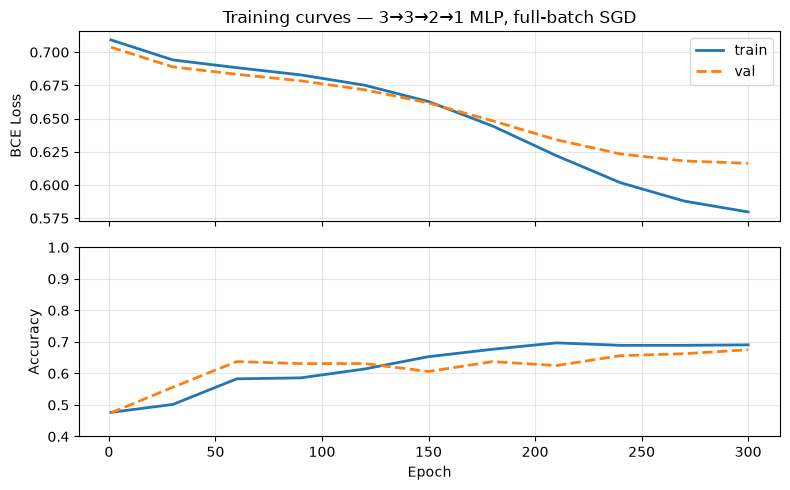

Final  train acc=0.691  val acc=0.675


In [23]:
epochs_x = [e["epoch"]      for e in history]
tr_losses = [e["train_loss"] for e in history]
vl_losses = [e["val_loss"]   for e in history]
tr_accs   = [e["train_acc"]  for e in history]
vl_accs   = [e["val_acc"]    for e in history]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)

ax1.plot(epochs_x, tr_losses, label="train", lw=2)
ax1.plot(epochs_x, vl_losses, label="val",   lw=2, linestyle="--")
ax1.set_ylabel("BCE Loss"); ax1.legend(); ax1.grid(alpha=0.3)
ax1.set_title("Training curves — 3→3→2→1 MLP, full-batch SGD")

ax2.plot(epochs_x, tr_accs, lw=2)
ax2.plot(epochs_x, vl_accs, lw=2, linestyle="--")
ax2.set_ylabel("Accuracy"); ax2.set_xlabel("Epoch"); ax2.grid(alpha=0.3)
ax2.set_ylim(0.4, 1.0)

fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "loss_curves.png", dpi=100, bbox_inches="tight")
plt.show()
print(f"Final  train acc={tr_accs[-1]:.3f}  val acc={vl_accs[-1]:.3f}")

**What we do:** Plot five per-layer time series: gradient norm, weight norm,
update ratio, activation std, and saturated-unit fraction.
**Why:** No single number tells the whole story. These five together let you
diagnose whether the network is learning well or silently failing.
**What you should see:** Five subplots with three coloured lines (L1, L2, L3).

---

**Definitions — what each metric is:**

| Metric | Definition |
|--------|-----------|
| **Gradient norm** `‖∇W‖` | The size of the gradient vector — `sqrt(sum of all squared partial derivatives of the loss w.r.t. every weight in that layer)`. It measures how strongly the loss depends on this layer's weights and sets the size of the optimizer step. |
| **Weight norm** `‖W‖` | The size of the weight matrix itself — `sqrt(sum of all squared weight values)`. A ruler for how large the layer's parameters have grown over training. |
| **Update ratio** `lr·‖∇W‖ / ‖W‖` | The size of the next update *relative* to the current weights. Answers: "compared to how big the weights already are, how big is the step we are about to take?" |
| **Activation std** `σ(z(l))` | Standard deviation of all post-activation outputs z(l) across the batch. Tells you how much variety there is in what the layer outputs — are neurons saying different things, or all the same thing? |
| **Saturated fraction** `\|z(l)\| > 0.95` | Fraction of tanh neurons whose output is within 5% of ±1 (the flat ends of the curve). A saturated neuron has a derivative close to 0, so almost no gradient flows through it. |

---

**Why we track each one:**

| Metric | Why |
|--------|-----|
| **Gradient norm** | If it collapses to zero, the layer has stopped receiving any learning signal — vanishing gradients. If it explodes, training will diverge. |
| **Weight norm** | If it grows unboundedly, weights are diverging. If it never moves, the layer is frozen. Watching it confirms weights are actually being updated. |
| **Update ratio** | Gradient norm alone is meaningless without context. A step of 0.1 is tiny if weights are 1000, but huge if weights are 0.01. The ratio normalises for that. |
| **Activation std** | A std near zero means all neurons fire the same value — the layer has collapsed and adds nothing. In a healthy layer the outputs differ across neurons and samples. |
| **Saturated fraction** | A saturated tanh has derivative ≈ 0, so it blocks the gradient from flowing backward. High sat_frac in a layer means little gradient flows through it to the layers before it. |

---

**Formula · What it measures · Healthy range · Warning sign:**

| Metric | Formula | What it measures | Healthy range | Warning sign |
|--------|---------|-----------------|--------------|--------------|
| **Gradient norm** | `sqrt(Σ (∂E/∂w)²)` | Magnitude of the error signal at this layer | Clearly above 0 and never blowing up; the shape follows the loss landscape (it can dip on a plateau, rise while the loss decreases fast, fall near convergence) | Near 0 from epoch 1 → vanishing; suddenly large → exploding |
| **Weight norm** | `sqrt(Σ w²)` | Magnitude of the layer's learned parameters | Slow, steady growth | Rapid growth → diverging; flat line → not being updated |
| **Update ratio** | `lr · ‖∇W‖ / ‖W‖` | Step size as a fraction of weight magnitude | 0.01 – 0.1 | Near 1 → updates as big as the weights (exploding); near 0 → no learning |
| **Activation std** | `std(z(l))` over batch | Diversity of neuron outputs | > 0.1, stable or growing | Near 0 → collapsed layer; very high → saturating |
| **Saturated fraction** | `mean(\|z\| > 0.95)` | Fraction of neurons in the tanh flat zone | Near 0 | Near 1 → most neurons dead, gradients blocked |

**Why saturation kills gradients:**
tanh derivative = `1 − tanh²(a)`. At `|tanh| = 0.95`, derivative = 0.097 — only 10% of the error signal passes through. Across three saturated layers the gradient at L1 is `0.097³ ≈ 0.001` of what it was at the output.

---

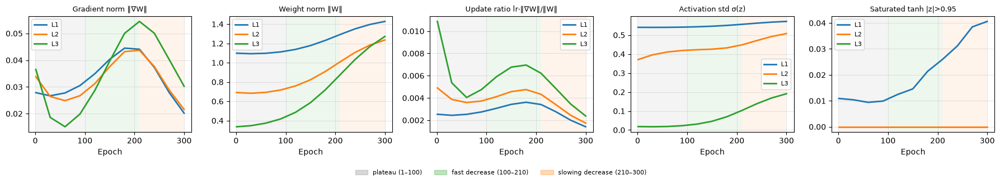

In [24]:
from matplotlib.patches import Patch

metrics = [
    ("grad_norm",    "Gradient norm ‖∇W‖"),
    ("weight_norm",  "Weight norm ‖W‖"),
    ("update_ratio", "Update ratio lr·‖∇W‖/‖W‖"),
    ("act_std",      "Activation std σ(z)"),
    ("sat_frac",     "Saturated tanh |z|>0.95"),
]
n_layers = len(model.layers)

PHASES = [(1, 100, "plateau (1–100)", "tab:grey"),            # our reading of this run, explained in the story below
          (100, 210, "fast decrease (100–210)", "tab:green"),
          (210, EPOCHS, "slowing decrease (210–300)", "tab:orange")]

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, (key, label) in zip(axes, metrics):
    for lo, hi, _, col in PHASES:
        ax.axvspan(lo, hi, color=col, alpha=0.08, lw=0)
    for l in range(n_layers):
        vals = [e.get(f"L{l+1}_{key}") for e in history]
        vals = [v if v is not None else float("nan") for v in vals]
        ax.plot(epochs_x, vals, label=f"L{l+1}", lw=2)
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.legend(handles=[Patch(color=c, alpha=0.3, label=n) for _, _, n, c in PHASES],
           loc="lower center", ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "layer_diagnostics.png", dpi=100, bbox_inches="tight")
plt.show()

## Why do the gradients behave like this? The fundamentals

**What we do:** Before reading the plots as a story, work out what the gradient of a layer consists of, and use it to explain why the gradient is small at the start, why the error signal δ becomes smaller toward the input layer, why the relative step size differs between layers, and why the loss decreases faster later.
**Why:** The five panels follow from a few facts about the backprop formulas.
**What you should see:** Numbers measured on this network at initialization in the next cell, with checks that every claim holds.

### Notation

```
a(l) = W(l) z(l-1) + b(l)         pre-activation of layer l          z(0) = x
z(l) = h(a(l))                    output of layer l (the input of layer l+1)
δ(l) = ∂E/∂a(l)                   error signal of layer l
δ(L) = y − t                      output layer, sigmoid + BCE
δ(l) = ( W(l+1)ᵀ δ(l+1) ) ⊙ (1 − z(l)²)      tanh layers, propagated backward
```

For one sample *i*, the **per-sample gradient** of the weights of layer *l* is `δᵢ(l) · zᵢ(l-1)ᵀ`. The gradient used by the optimizer is the **mean of the per-sample gradients**:

```
∂E/∂W(l) = (1/N) Σᵢ  δᵢ(l) · zᵢ(l-1)ᵀ
```

### 1. What the gradient of a layer depends on

Each per-sample gradient is the product of two factors: the error signal δᵢ(l) and the layer input zᵢ(l-1) (for layer 1 the input is x). The gradient is the mean over samples. Two consequences:

- if δ is small, the per-sample gradients are small;
- if the per-sample gradients of different samples have **opposite signs**, they cancel in the mean.

We measure the cancellation with the ratio `mean ‖gᵢ‖ / ‖mean g‖`, where `gᵢ` is the per-sample gradient. It is at least 1, and it equals 1 only if all per-sample gradients are equal.

### 2. Why the gradient is small at the start

**(a) Cancellation.** At initialization the output is about 0.5 for all samples, so `δ(3) = y − t` is about +0.5 for samples with t = 0 and about −0.5 for samples with t = 1, while the layer input z(2) is almost unrelated to t. The per-sample gradients have opposite signs and average out. Measured at initialization, the mean per-sample gradient norm of W(3) is 0.26 and the norm of the mean is only 0.037: a cancellation ratio of about 7 (about 3.9 for W(2) and 3.1 for W(1)).

**(b) The gradient is the covariance of δ and the layer input.** `mean(δᵢ zᵢ)` equals `Cov(δ, z)` when `mean(δ) = 0`. If the activations are uncorrelated with the label, this covariance is close to 0. At initialization the largest correlation between any activation and the label is 0.36; after training it is 0.47. Learning means that the activations start to carry information about the label.

**(c) δ is multiplied by small weights** while it is propagated backward (next point).

### 3. Why δ becomes smaller toward the input, and why the relative step sizes differ

In `δ(l) = (W(l+1)ᵀ δ(l+1)) ⊙ (1 − z(l)²)` every step back multiplies by `W(l+1)ᵀ` (small at the start) and by a derivative that is at most 1. So δ shrinks from the output toward the input. Measured at initialization, the rms of δ is 0.51 at the output, 0.10 in layer 2 and 0.035 in layer 1.

The three **gradient norms** are nevertheless similar (0.037, 0.034, 0.028), because the layer input is larger toward the input layer (rms of z(l-1): 1.0 for x, 0.54 for z(1), 0.37 for z(2)): the smaller δ is multiplied by a larger z.

What differs between the layers is the step relative to the weights, the update ratio `lr·‖∇W‖ / ‖W‖`: 0.011 for the output layer, 0.005 for layer 2 and 0.0025 for layer 1. The gradient norms are similar but ‖W‖ is 0.34, 0.69 and 1.10, so the earlier layers change less in relative terms. The gradient of an earlier layer also depends on the weights of all later layers, because δ is propagated through them.

### 4. Why the start is slow, and why the size of the initial weights matters

Small weights give a small δ in the earlier layers and strong cancellation, so the gradient is small and the weights change little. As the weights grow, δ in the earlier layers grows and the activations start to correlate with the label, so the cancellation decreases, the gradient grows and the weights change faster. This **positive feedback between the weight size and the gradient** produces a slow start followed by an acceleration.

The next cell tests it by scaling all initial weights:

- ×0.25: no progress. The loss is still 0.692 after 300 epochs and the gradients are about 0.003.
- ×0.5: the fast decrease only starts near the end (loss 0.647 at epoch 300).
- ×1 (ours), ×2, ×3: they start faster (loss at epoch 100: 0.681, 0.664, 0.659) but larger initial weights start at a higher loss (epoch 1: 0.71, 0.73, 0.76), because large random weights give confident wrong predictions. Very large weights also drive tanh into saturation, where `1 − z² ≈ 0`.

### 5. Why the decrease slows down again

Samples that are already classified correctly have a small δ. The samples that remain need a different kind of feature, and their per-sample gradients partly cancel again, so the gradient falls until the network finds such a feature. The weight heatmaps below show what the network has and has not learned by epoch 300.

One more fact: with a sigmoid output and cross-entropy loss, `δ(3) = y − t`, because the sigmoid derivative `y(1 − y)` (at most 0.25) cancels. With a squared-error loss it would not: `δ(3) = (y − t)·y(1 − y)`.

### What you will see in the plots, and the fact behind it

| In the plot | The fact behind it |
|---|---|
| gradient norm dips, then rises | cancellation and small δ at the start, then the positive feedback between weight size and gradient |
| weight norm flat, then growing | the same mechanism: small updates first, larger updates once the gradient has grown |
| update ratio: L3 > L2 > L1 | similar gradient norms, but larger weight norms in the earlier layers |
| output σ very small at first | small output weights and little information about the label in the activations |
| saturated fraction: L1 > L2 | layer 1 receives the standardized inputs (outliers up to ±3), layer 2 only receives z(1) in (−1, 1) |

In [25]:
import numpy as np


def fresh_model(scale=1.0):
    torch.manual_seed(SEED)
    m = MLP(LAYER_SIZES).to(device)
    with torch.no_grad():
        for prm in m.parameters():
            prm.mul_(scale)
    return m


Xt = torch.tensor(X_train).to(device)
yt = torch.tensor(y_train, dtype=torch.float32).to(device).unsqueeze(1)
rms = lambda t: float(t.pow(2).mean().sqrt())

m0 = fresh_model()
p1 = m0.layers[0](Xt); h1 = m0.acts[0](p1)
p2 = m0.layers[1](h1); h2 = m0.acts[1](p2)
p3 = m0.layers[2](h2); h3 = m0.acts[2](p3)
for t in (p1, p2, p3):
    t.retain_grad()
F.binary_cross_entropy(h3, yt, reduction="sum").backward()
delta = {3: p3.grad, 2: p2.grad, 1: p1.grad}
layer_input = {3: h2.detach(), 2: h1.detach(), 1: Xt}

print("at initialization (one pass over the training set)")
print(f"{'layer':<7}{'rms δ':>9}{'rms z(l-1)':>12}{'mean ‖gᵢ‖':>12}{'‖mean g‖':>10}{'cancellation':>14}{'‖W‖':>8}{'update ratio':>14}")
cancel, ratio, rms_delta, rms_input = {}, {}, {}, {}
for l in (3, 2, 1):
    d, zin, Wl = delta[l], layer_input[l], m0.layers[l - 1].weight
    per_sample = d.unsqueeze(2) * zin.unsqueeze(1)
    mean_norm, norm_of_mean = float(per_sample.flatten(1).norm(dim=1).mean()), float(per_sample.mean(0).norm())
    cancel[l], ratio[l] = mean_norm / norm_of_mean, LR * norm_of_mean / float(Wl.norm())
    rms_delta[l], rms_input[l] = rms(d), rms(zin)
    print(f"L{l:<6}{rms_delta[l]:>9.3f}{rms_input[l]:>12.3f}{mean_norm:>12.3f}{norm_of_mean:>10.3f}{cancel[l]:>13.1f}x{float(Wl.norm()):>8.3f}{ratio[l]:>14.4f}")


def label_corr(m):
    with torch.no_grad():
        z_a = m.acts[0](m.layers[0](Xt)); z_b = m.acts[1](m.layers[1](z_a)); z_c = m.acts[2](m.layers[2](z_b))
    return max(abs(float(np.corrcoef(z[:, k].cpu().numpy(), y_train)[0, 1])) for z in (z_a, z_b, z_c) for k in range(z.shape[1]))


corr_init, corr_trained = label_corr(m0), label_corr(model)
print(f"\nlargest |correlation| between any activation and the label: initial {corr_init:.2f}, after training {corr_trained:.2f}")


def train_scaled(scale, epochs=300):
    m = fresh_model(scale)
    opt = torch.optim.SGD(m.parameters(), lr=LR)
    out = {}
    for ep in range(1, epochs + 1):
        opt.zero_grad()
        loss = F.binary_cross_entropy(m(Xt), yt)
        loss.backward()
        if ep in (1, 100, 300):
            out[ep] = (loss.item(), float(m.layers[0].weight.grad.norm()))
        opt.step()
    return out


scaled = {s: train_scaled(s) for s in (0.25, 0.5, 1.0, 2.0, 3.0)}
print("\ninitial weights scaled (loss at epoch 1 / 100 / 300, and the layer-1 gradient norm at epoch 300):")
for s, r in scaled.items():
    print(f"  x{s:<5}: loss {r[1][0]:.3f} / {r[100][0]:.3f} / {r[300][0]:.3f}    ‖grad L1‖ at 300 = {r[300][1]:.4f}")

assert rms_delta[3] > rms_delta[2] > rms_delta[1], "FAIL: the error signal does not shrink toward the input"
assert rms_input[1] > rms_input[2] > rms_input[3], "FAIL: the layer input does not grow toward the input layer"
assert all(cancel[l] > 2 for l in (1, 2, 3)) and cancel[3] > 5, "FAIL: the per-sample gradients do not cancel"
assert ratio[3] > ratio[2] > ratio[1], "FAIL: the update ratio does not grow toward the output"
assert corr_init < 0.45 and corr_trained > corr_init, "FAIL: the activations do not gain information about the label"
assert scaled[0.25][300][0] > 0.68 and scaled[1.0][300][0] < 0.62 and scaled[0.5][300][0] > scaled[1.0][300][0], "FAIL: initial-scale experiment"
assert scaled[3.0][1][0] > scaled[1.0][1][0], "FAIL: larger initial weights should start at a higher loss"
print("\nPASS: the fundamentals hold on this network (cancellation, shrinking δ, initial weight size)")

at initialization (one pass over the training set)
layer      rms δ  rms z(l-1)   mean ‖gᵢ‖  ‖mean g‖  cancellation     ‖W‖  update ratio
L3         0.508       0.371       0.257     0.037          7.0x   0.336        0.0109
L2         0.105       0.543       0.132     0.034          3.9x   0.691        0.0049
L1         0.035       1.000       0.087     0.028          3.1x   1.098        0.0025

largest |correlation| between any activation and the label: initial 0.36, after training 0.47



initial weights scaled (loss at epoch 1 / 100 / 300, and the layer-1 gradient norm at epoch 300):
  x0.25 : loss 0.695 / 0.692 / 0.692    ‖grad L1‖ at 300 = 0.0040
  x0.5  : loss 0.699 / 0.691 / 0.647    ‖grad L1‖ at 300 = 0.0455
  x1.0  : loss 0.709 / 0.681 / 0.580    ‖grad L1‖ at 300 = 0.0202
  x2.0  : loss 0.732 / 0.664 / 0.587    ‖grad L1‖ at 300 = 0.0383
  x3.0  : loss 0.759 / 0.659 / 0.587    ‖grad L1‖ at 300 = 0.0410

PASS: the fundamentals hold on this network (cancellation, shrinking δ, initial weight size)


## The story of this run, plot by plot

**What we do:** Read the five diagnostic panels together for *this* run: a 3→3→2→1 MLP, tanh / tanh / sigmoid, full-batch SGD, lr = 0.1, 300 epochs.
**Why:** One panel alone is just a squiggle. Together they tell one story of what the network was doing at each stage of training. The three shaded bands on the plot mark the stages.
**What you should see:** The numbers behind every sentence below, printed in the next cell, with checks that they hold.

*All numbers are from the executed run. A re-run can differ in the last digits; the shape of the story should not.*

### The story in one paragraph

The untrained network answers about 0.5 for every sample (output-layer σ ≈ 0.02). For the first ~100 epochs it is on a **plateau**: gradients are small, the weights barely change and the loss decreases slowly. Around epoch 100 the loss starts to **decrease fast**: gradient norms rise to a peak near epochs 180–210, the weights grow (the output layer most) and the predictions start to spread out. After epoch ~210 the **decrease slows**: gradients shrink again, but the weights are still growing and the network has **not converged**. There are no vanishing or exploding gradients, no collapsed layer and no saturation to speak of. The run is healthy but under-trained.

### Panel by panel

**1. Gradient norm** — all three layers start at 0.028–0.037, **dip** (the output layer falls from 0.037 to 0.015 by epoch 60), then **rise** to a peak around epochs 180–210 (L1 0.045, L2 0.044, L3 0.054) and fall back to 0.02–0.03.
*Why:* see the fundamentals above. δ is multiplied by the weights while it is propagated backward, and the weights start small, so δ is small in the earlier layers; and the per-sample gradients cancel while the activations carry little information about the label. The easy part (matching the 52 / 48 class balance with the output bias) is probably learned in the first epochs, which is why the gradient shrinks at first. As the weights grow, δ in the earlier layers grows, the activations start to carry the label and the cancellation decreases, so the gradients rise. Near a minimum of the loss the gradient flattens again.
*Verdict:* a rise and fall, not the textbook steady decrease (the animation drew the idealised shape). What matters is that it never reaches 0 and never blows up, and that **layer 1 has about the same gradient norm as the output layer**: the gradient does not vanish in the earlier layers.

**2. Weight norm** — flat for ~90 epochs, then growing: L1 1.10 → 1.43 (+30 %), L2 0.69 → 1.24 (+80 %), L3 0.34 → 1.27 (almost ×4).
*Why:* the output layer starts smallest, and to move a prediction away from 0.5 its weights must grow. The hidden layers change less. The three norms end up at a similar size.
*Verdict:* the weights of every layer change and none grows without bound.

**3. Update ratio** — between 0.0014 and 0.011, mostly **below** the 0.01 – 0.1 rule-of-thumb band. It follows the gradient norm (the ratio is `lr·‖∇W‖ / ‖W‖`): a dip, a maximum near epoch 180, then a decrease. For L2 and L3 the very first epoch is still the highest point. L3 is highest throughout because its weights are smallest.
*Verdict:* safe (nowhere near 1) but cautious. Each step is only 0.1 – 1 % of the weights, so learning is slow, and the loss was still falling at epoch 300. Below the band means *slow* here, not *stalled*. (The 0.01 – 0.1 band is a rule of thumb from larger networks and Adam.)

**4. Activation std** — L1 stays near 0.54 – 0.57, L2 rises from 0.37 to 0.51, L3 rises from 0.018 to 0.19.
L3 is the **sigmoid output**, so its σ is the spread of the *predictions*. 0.018 at epoch 1 means that all predictions are about 0.5; the rise to 0.19 means the predictions spread out, some towards each class. It crosses 0.1 near epoch 205, just as the loss starts to decrease faster.
*Verdict:* the one panel where a low σ is **not** a warning: the output layer should start narrow and widen. The hidden layers never come near 0, so nothing collapsed.

**5. Saturated fraction** — L1 rises slowly from 1.1 % to 4.1 %, L2 stays at exactly 0, and L3 has no line (it is a sigmoid; `sat_frac` is only measured for tanh).
*Why L1 > L2:* layer 1 sees the standardized inputs, whose outliers reach ±3, so some of its sums are large. Layer 2 only sees z⁽¹⁾, which is bounded in (−1, 1), so its sums stay small. The rise of L1 follows its weight norm (1.10 → 1.43): larger weights give larger pre-activations, so more outputs move toward ±1.
*Verdict:* tiny and harmless here, but a slow rise like this is what to watch if we trained much longer or with a larger lr.

### How the panels connect

weights start small → backprop gives weak gradients → tiny steps (update ratio) → weights barely move → the output stays near 0.5 (σ of L3 tiny) → **plateau**.
Output weights grow → δ in the earlier layers grows and the cancellation decreases → gradients rise → bigger steps → σ of L3 increases → the loss decreases faster → **fast decrease**.
The slope flattens → gradients and update ratios fall → the weights are still growing and `sat_frac` of L1 is still rising → **slowing decrease**, not converged.

### What the plots suggest doing next

More epochs or a larger lr would speed this up (the update ratio is far below the band). Expect diminishing returns on validation, though: the train and validation losses are starting to separate (about 0.580 vs 0.616 at epoch 300). And keep an eye on `sat_frac` of layer 1, which should stay well below 0.5.

In [26]:
import numpy as np


def series(key, l):
    return [e.get(f"L{l+1}_{key}") for e in history]


print(f"{'metric':<14}{'layer':<7}{'first':>10}{'peak':>10}{'last':>10}{'peak at epoch':>16}")
for key, _ in metrics:
    for l in range(n_layers):
        v = series(key, l)
        if v[0] is None:
            continue
        print(f"{key:<14}{'L' + str(l + 1):<7}{v[0]:>10.4g}{max(v):>10.4g}{v[-1]:>10.4g}{epochs_x[int(np.argmax(v))]:>16}")

all_grads = [g for l in range(n_layers) for g in series("grad_norm", l)]
assert 1e-3 < min(all_grads) and max(all_grads) < 1.0, "FAIL: gradients vanished or exploded"
assert all(series("weight_norm", l)[-1] > series("weight_norm", l)[0] for l in range(n_layers)), "FAIL: a layer did not grow"
assert max(r for l in range(n_layers) for r in series("update_ratio", l)) < 0.1, "FAIL: update ratio reached the unstable side"
assert min(min(series("act_std", l)) for l in range(2)) > 0.1, "FAIL: a hidden layer collapsed"
assert series("act_std", 2)[-1] > 2 * series("act_std", 2)[0], "FAIL: output predictions did not spread out"
assert max(max(series("sat_frac", l)) for l in range(2)) < 0.1, "FAIL: tanh neurons saturated"
print("\nPASS: the story holds for this run (no vanishing or exploding gradients, no collapse, no saturation)")

metric        layer       first      peak      last   peak at epoch
grad_norm     L1        0.02785    0.0445   0.02019             180
grad_norm     L2        0.03385   0.04368   0.02155             210
grad_norm     L3        0.03654   0.05448   0.03025             210
weight_norm   L1          1.098     1.428     1.428             300
weight_norm   L2         0.6911     1.235     1.235             300
weight_norm   L3         0.3362     1.272     1.272             300
update_ratio  L1       0.002535  0.003614  0.001414             180
update_ratio  L2       0.004899  0.004899  0.001744               1
update_ratio  L3        0.01087   0.01087  0.002379               1
act_std       L1         0.5408    0.5719    0.5719             300
act_std       L2          0.371    0.5079    0.5079             300
act_std       L3        0.01807     0.191     0.191             300
sat_frac      L1         0.0109    0.0406    0.0406             300
sat_frac      L2              0         0       

**What we do:** Play the story of this run as an animation, slowly, one plot at a time.
**Why:** The text above explains each plot. Watching the curves being drawn, and the reasons appearing one at a time, makes the chain of cause and effect easier to follow.
**What you should see:** One video (~6 min), then a PASS. For each plot it goes through *what we see*, *why*, and *so what*.

| Part of the video | What it shows |
|---|---|
| The loss | the anchor curve and its three stages: plateau, fast decrease, slowing decrease |
| 1 · Gradient norm | the dip, the peak near epochs 180–210, and why: backprop multiplies by the weights, small at the start |
| 2 · Weight norm | flat, then growth, the output layer ×3.8: bars at epoch 1 vs epoch 300 |
| 3 · Update ratio | the curves against the 0.01–0.1 band on a log scale, and a step drawn next to the weights it changes |
| 4 · Activation std | why the output layer's low σ at the start is expected: the predictions spread out, drawn as dots |
| 5 · Saturated fraction | why layer 1 rises slowly and layer 2 stays at 0: the range of the sums against tanh's flat ends |
| How they connect, verdict | one table of the three stages, the cause-and-effect chain, and what to do next |

The scene draws the logged numbers of the run shown above (they are stored in the scene file). If you change the training settings, update `DATA` in `tools/manim/training_story.py` before re-rendering.

Scene source: `tools/manim/training_story.py` (`TrainingStory`). Re-render: `manim -r 1280,720 --fps 15 tools/manim/training_story.py TrainingStory`, then copy the mp4 into `artifacts/manim/`.

In [27]:
from IPython.display import Video, display

path = ARTIFACTS_DIR / "manim" / "TrainingStory.mp4"
assert path.exists(), "FAIL: TrainingStory.mp4 missing — run: manim -r 1280,720 --fps 15 tools/manim/training_story.py TrainingStory"
display(Video(str(path), embed=True, width=800))
print("PASS: training-story animation found")

PASS: training-story animation found


**What we do:** Play one animation per diagnostic metric from the five plots above, plus one that contrasts activation std with saturated fraction.
**Why:** The plots show the numbers over time; the animations show what each number *is*, how it is computed, how it behaves across epochs in the healthy and warning cases, and how two similar-looking metrics differ.
**What you should see:** Six short videos (~30-40 s each), then a PASS. Each one explains the metric in plain words and has a legend naming every coloured line, dot or bar.

| Animation | Plot panel | What it shows |
|---|---|---|
| `GradientNorm` | Gradient norm `‖∇W‖` | Square every gradient entry, sum, square root (worked example = 3); curves over epochs for healthy, vanishing, exploding |
| `WeightNorm` | Weight norm `‖W‖` | Same recipe on `W` (worked example = 5); curves over epochs for healthy, frozen, diverging |
| `UpdateRatio` | Update ratio `lr·‖∇W‖/‖W‖` | The step as a bar next to the weights' bar, then the ratio over epochs on a log scale: too small, the healthy 0.01 – 0.1 band, too big |
| `ActivationStd` | Activation std `σ(z)` | Neuron outputs as dots with `μ ± σ`, then σ over epochs: stable, collapsing below 0.1, saturating toward 1 |
| `SaturatedFraction` | Saturated tanh `\|z\|>0.95` | Dots turn orange inside the flat zone, then `sat_frac` over epochs: stays near 0, rises slowly, close to 1 |
| `ActStdVsSatFrac` | Activation std vs saturated tanh | Four neuron-output patterns with both numbers computed: σ misses saturation at ±1, `sat_frac` misses collapse in the middle, so both are tracked |

Scene source: `tools/manim/*.py`. Re-render one with `manim -r 1280,720 --fps 15 tools/manim/<file>.py <SceneName>` and copy the mp4 into `artifacts/manim/`.

In [28]:
from IPython.display import Video, display

MANIM_DIR = ARTIFACTS_DIR / "manim"
metric_scenes = [
    ("GradientNorm",      "1) Gradient norm  ‖∇W‖"),
    ("WeightNorm",        "2) Weight norm  ‖W‖"),
    ("UpdateRatio",       "3) Update ratio  lr·‖∇W‖ / ‖W‖"),
    ("ActivationStd",     "4) Activation std  σ(z)"),
    ("SaturatedFraction", "5) Saturated fraction  |z| > 0.95"),
    ("ActStdVsSatFrac",   "6) Activation std vs saturated fraction — what each one sees"),
]

for name, caption in metric_scenes:
    path = MANIM_DIR / f"{name}.mp4"
    assert path.exists(), f"FAIL: {path.name} missing — render it with manim (see markdown above)"
    print(caption)
    display(Video(str(path), embed=True, width=800))

print("PASS: all metric animations found")

1) Gradient norm  ‖∇W‖


2) Weight norm  ‖W‖


3) Update ratio  lr·‖∇W‖ / ‖W‖


4) Activation std  σ(z)


5) Saturated fraction  |z| > 0.95


6) Activation std vs saturated fraction — what each one sees


PASS: all metric animations found


**What we do:** Show each layer's weight matrix at epoch 0, final epoch, and
the change (after − before) as colour maps.
**Why:** Colours make the direction and magnitude of each weight update visible
at a glance — which weights moved the most, and in which direction.
**What you should see:** A 3-row × 3-column grid of heatmaps.

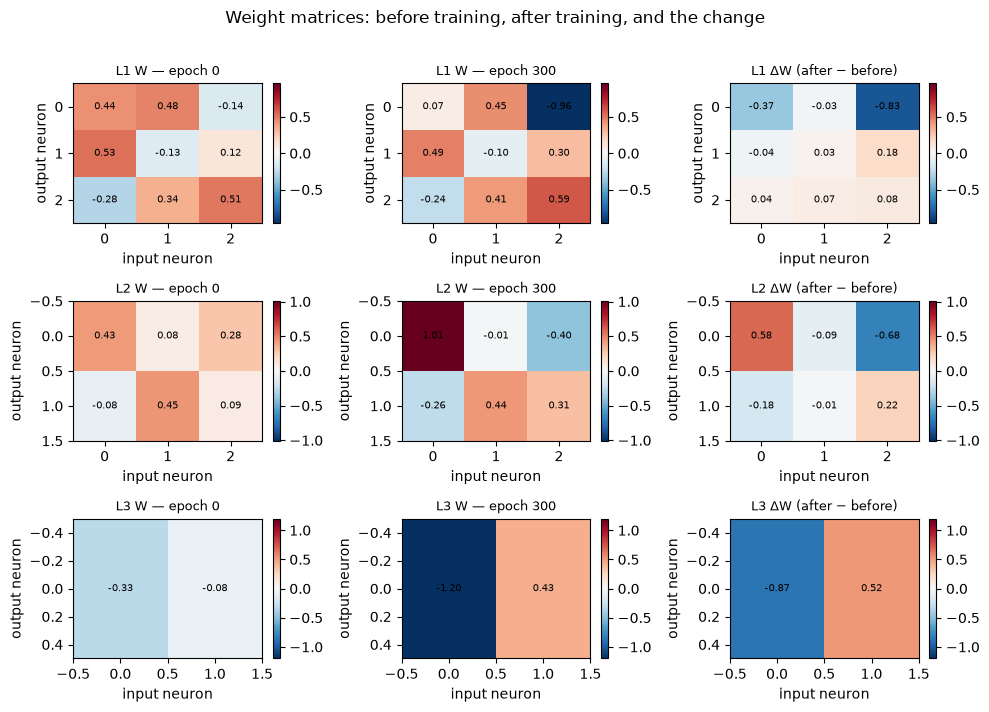

In [29]:
snap_before = weight_snaps[0]
snap_after  = weight_snaps[EPOCHS]
layer_names = [f"L{l+1}" for l in range(n_layers)]

fig, axes = plt.subplots(n_layers, 3, figsize=(10, 7))
for row, ln in enumerate(layer_names):
    W_before = snap_before[f"{ln}_W"]
    W_after  = snap_after[f"{ln}_W"]
    W_delta  = W_after - W_before
    vmax = max(abs(W_before).max(), abs(W_after).max(), abs(W_delta).max()) + 1e-6

    for col, (mat, title) in enumerate([
        (W_before, f"{ln} W — epoch 0"),
        (W_after,  f"{ln} W — epoch {EPOCHS}"),
        (W_delta,  f"{ln} ΔW (after − before)"),
    ]):
        ax = axes[row, col]
        im = ax.imshow(mat, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
        ax.set_title(title, fontsize=9)
        ax.set_xlabel("input neuron"); ax.set_ylabel("output neuron")
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                ax.text(j, i, f"{mat[i,j]:.2f}", ha="center", va="center",
                        fontsize=7, color="k")
        plt.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle("Weight matrices: before training, after training, and the change", y=1.01)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "weight_heatmaps.png", dpi=100, bbox_inches="tight")
plt.show()

## The story of the weight heatmaps

**What we do:** Read the heatmaps above as a story: which of the 17 weights changed, in which direction, and what the network has learned from that.
**Why:** The diagnostics said the run is healthy but under-trained. The heatmaps show *what* the network has actually learned so far.
**What you should see:** The numbers behind every sentence below, printed in the next cell, with checks that they hold.

*All numbers are from the executed run. A re-run can differ in the last digits; the shape of the story should not.*

### How to read the figure

| In the plot | Meaning |
|---|---|
| a row | one neuron of this layer |
| a column | one input coming into the layer (x₁, x₂, x₃ for layer 1; the layer-1 outputs z for layer 2; the layer-2 outputs for layer 3) |
| a cell | the weight connecting that input to that neuron |
| red / blue | positive / negative (white is near zero) |
| left, middle, right | epoch 0, epoch 300, and the change (after − before) |
| colour scale | shared by the three tables of one layer, different between layers: compare colours *within* a layer, not across layers |

The plot shows the 17 weights. The 6 biases are not in it.

### The story in one paragraph

Training did not change the 17 weights equally. In each layer a handful of weights carry almost all of the change: three of nine in layer 1, three of six in layer 2, both in layer 3. Together they form one path from the input **x₃** to the output, and the signs along it agree (−, +, −: two minuses make a plus, so a larger x₃ gives a larger output). Two tests confirm it: the network's output follows x₃ (correlation +0.93) and not the squares x₁², x₂² (about 0), and shuffling x₃ drops the accuracy to chance while shuffling x₁ or x₂ changes nothing. So after 300 epochs the network has learned only the **straight part** of the rule (`+ x₃`) and has not started on the **curved part** (`x₁² − x₂²`). That is what *under-trained* means here. Training for longer does start on the curve.

### Layer by layer

**Layer 1 (3 × 3)** — Three weights change much. Neuron 1 ← x₃ goes from −0.14 to −0.96 (the biggest change of all), neuron 1 ← x₁ falls from 0.44 to 0.08, and neuron 2 ← x₃ rises from 0.12 to 0.30. Together they carry 98 % of the squared change. The x₂ column barely changes (every change is below 0.07).
*Verdict:* layer 1 has concentrated on x₃.

**Layer 2 (2 × 3)** — Neuron 1 ← z₁ grows from 0.43 to 1.01, and neuron 1 ← z₃ falls from +0.28 to −0.41, so it **changes sign**. Three weights carry 96 % of the change.
*Verdict:* layer 2 depends more and more on layer-1 neuron 1, the neuron that carries x₃.

**Layer 3 (1 × 2)** — Both weights move a lot: −0.33 → −1.20 and −0.08 → +0.43 (a sign change). Relative to its starting size this layer changed the most (‖ΔW‖ is about three times ‖W(0)‖, against 0.85 for layer 1 and 1.4 for layer 2), which matches the weight-norm panel.

### The path from x₃ to the output

The largest weights form a path: x₃ → layer-1 neuron 1 (−0.96) → layer-2 neuron 1 (+1.01) → output (−1.20). The product of the three is positive, so when x₃ increases, the activation of layer-1 neuron 1 decreases, that of layer-2 neuron 1 decreases, and the output **increases**. There are six paths from x₃ to the output; **all six products are positive**, so every path agrees, and the main path carries about 68 % of the total. The snapshots at epochs 100 and 200 show the weights of the path growing steadily, mostly after epoch 100: the fast-decrease phase of the diagnostics story, seen in the weights.

### Is it really only x₃?

- **Correlation.** The network's output (as a logit) correlates +0.93 with x₃ and about 0 with x₁², x₂² and x₁² − x₂².
- **Shuffling.** Mixing up one input at a time: x₁ or x₂ changes the training accuracy by less than 1 %; x₃ drops it from 0.69 to 0.50, which is chance.
- **A yardstick.** The plain rule "x₃ > 0" scores 70.8 % on the same labels, slightly *more* than the network's 69.1 %. The network has found that rule and nothing beyond it.

### What it means, and what comes next

The label is `x₁² − x₂² + x₃ > 0`: a curved part plus a straight part. Our reading: with small weights tanh is almost a straight line, so a straight-line feature is the first thing a network can pick up; squares need the neurons to bend. To see whether more training moves on to the curve, the next cell trains the same network (same start, same learning rate) for 3000 epochs and measures the same things at epochs 300, 1000 and 3000. It is a check, not part of the main run.

In [30]:
import numpy as np

Wsnap = {l: {ep: weight_snaps[ep][f"L{l}_W"] for ep in sorted(weight_snaps)} for l in (1, 2, 3)}

print("largest weight changes, epoch 0 -> 300")
top3_share = {}
for l in (1, 2, 3):
    d = Wsnap[l][EPOCHS] - Wsnap[l][0]
    sq = np.sort((d ** 2).ravel())[::-1]
    top3_share[l] = sq[:3].sum() / sq.sum()
    for idx in np.argsort(-np.abs(d), axis=None)[:3]:
        j, i = np.unravel_index(idx, d.shape)
        print(f"  L{l} neuron {j + 1} <- input {i + 1}: {Wsnap[l][0][j, i]:+.3f} -> {Wsnap[l][EPOCHS][j, i]:+.3f}")
    print(f"  L{l}: top-3 weights carry {top3_share[l]:.0%} of the squared change;  ‖ΔW‖/‖W(0)‖ = {np.linalg.norm(d) / np.linalg.norm(Wsnap[l][0]):.2f}")

w1, w2, w3 = (Wsnap[l][EPOCHS] for l in (1, 2, 3))
routes = {(j, k): w1[j, 2] * w2[k, j] * w3[0, k] for j in range(3) for k in range(2)}
print("\nstrongest path over the snapshots (x3 -> L1 n1 -> L2 n1 -> output):")
for ep in sorted(weight_snaps):
    print(f"  epoch {ep:>3}: {Wsnap[1][ep][0, 2]:+.3f}  {Wsnap[2][ep][0, 0]:+.3f}  {Wsnap[3][ep][0, 0]:+.3f}")
print("six paths from x3 to the output:", "  ".join(f"{v:+.2f}" for v in sorted(routes.values(), reverse=True)))


def predict(Xs):
    with torch.no_grad():
        return model(torch.tensor(Xs, dtype=torch.float32).to(device)).cpu().numpy().ravel()


truth = y_train.astype(bool)
probs = predict(X_train)
base_acc = float(((probs > 0.5) == truth).mean())
rng = np.random.default_rng(0)
shuffled = {}
for j, name in enumerate(["x1", "x2", "x3"]):
    accs = []
    for _ in range(50):
        Xs = X_train.copy()
        Xs[:, j] = rng.permutation(Xs[:, j])
        accs.append(float(((predict(Xs) > 0.5) == truth).mean()))
    shuffled[name] = float(np.mean(accs))
logit = np.log(probs / (1 - probs))
fx1, fx2, fx3 = X_train_raw.T
corr = {n: float(np.corrcoef(logit, t)[0, 1]) for n, t in
        [("x3", fx3), ("x1²", fx1 ** 2), ("x2²", fx2 ** 2), ("x1²−x2²", fx1 ** 2 - fx2 ** 2)]}
rule_acc = float(((fx3 > 0) == truth).mean())
print("\ncorrelation of the output with:", "  ".join(f"{n} {v:+.3f}" for n, v in corr.items()))
print(f"accuracy {base_acc:.4f};  after shuffling x1 / x2 / x3: " + " / ".join(f"{shuffled[n]:.4f}" for n in ("x1", "x2", "x3")))
print(f"the plain rule 'x3 > 0' scores {rule_acc:.4f} on the same labels")


def train_probe(checkpoints=(300, 1000, 3000)):
    torch.manual_seed(SEED)
    m = MLP(LAYER_SIZES).to(device)
    opt = torch.optim.SGD(m.parameters(), lr=LR)
    Xt = torch.tensor(X_train).to(device)
    yt = torch.tensor(y_train, dtype=torch.float32).to(device).unsqueeze(1)
    Xv = torch.tensor(X_val).to(device)
    yv = torch.tensor(y_val, dtype=torch.float32).to(device).unsqueeze(1)
    out = {}
    for ep in range(1, max(checkpoints) + 1):
        opt.zero_grad()
        F.binary_cross_entropy(m(Xt), yt).backward()
        opt.step()
        if ep in checkpoints:
            with torch.no_grad():
                pt = m(Xt).cpu().numpy().ravel()
                va = float(((m(Xv) > 0.5) == yv.bool()).float().mean())
            lg = np.log(np.clip(pt, 1e-6, 1) / np.clip(1 - pt, 1e-6, 1))
            out[ep] = dict(val=va, cx3=float(np.corrcoef(lg, fx3)[0, 1]), ccurve=float(np.corrcoef(lg, fx1 ** 2 - fx2 ** 2)[0, 1]))
    return out


probe = train_probe()
print("\nsame network trained longer (a check, not the main run):")
for ep, r in probe.items():
    print(f"  epoch {ep:>4}: val acc {r['val']:.3f}   follows x3 {r['cx3']:+.2f}   follows x1²−x2² {r['ccurve']:+.2f}")

assert top3_share[1] > 0.9 and top3_share[2] > 0.9, "FAIL: the change is not concentrated in a few weights"
assert all(v > 0 for v in routes.values()), "FAIL: the paths from x3 disagree in sign"
assert max(routes.values()) / sum(routes.values()) > 0.5, "FAIL: no dominant path"
assert corr["x3"] > 0.8 and abs(corr["x1²−x2²"]) < 0.2, "FAIL: output does not follow x3 only"
assert base_acc - shuffled["x3"] > 0.1 and abs(base_acc - shuffled["x1"]) < 0.03 and abs(base_acc - shuffled["x2"]) < 0.03, "FAIL: shuffling test"
assert abs(probe[300]["val"] - val_acc) < 0.02, "FAIL: the probe does not reproduce the main run"
assert probe[3000]["ccurve"] > 0.4 and probe[3000]["val"] > 0.85, "FAIL: longer training did not start on the curve"
print("\nPASS: the story holds (a chain for x3, the straight part learned, the curve not yet, longer training starts on it)")

largest weight changes, epoch 0 -> 300
  L1 neuron 1 <- input 3: -0.135 -> -0.961
  L1 neuron 1 <- input 1: +0.441 -> +0.075
  L1 neuron 2 <- input 3: +0.117 -> +0.295
  L1: top-3 weights carry 98% of the squared change;  ‖ΔW‖/‖W(0)‖ = 0.85
  L2 neuron 1 <- input 3: +0.278 -> -0.405
  L2 neuron 1 <- input 1: +0.427 -> +1.007
  L2 neuron 2 <- input 3: +0.085 -> +0.307
  L2: top-3 weights carry 96% of the squared change;  ‖ΔW‖/‖W(0)‖ = 1.37
  L3 neuron 1 <- input 1: -0.326 -> -1.199
  L3 neuron 1 <- input 2: -0.083 -> +0.434
  L3: top-3 weights carry 100% of the squared change;  ‖ΔW‖/‖W(0)‖ = 3.02

strongest path over the snapshots (x3 -> L1 n1 -> L2 n1 -> output):
  epoch   0: -0.135  +0.427  -0.326
  epoch 100: -0.375  +0.564  -0.434
  epoch 200: -0.729  +0.826  -0.797
  epoch 300: -0.961  +1.007  -1.199
six paths from x3 to the output: +1.16  +0.29  +0.11  +0.08  +0.06  +0.00

correlation of the output with: x3 +0.929  x1² -0.043  x2² -0.018  x1²−x2² -0.016
accuracy 0.6906;  after shu


same network trained longer (a check, not the main run):
  epoch  300: val acc 0.675   follows x3 +0.93   follows x1²−x2² -0.02
  epoch 1000: val acc 0.762   follows x3 +0.80   follows x1²−x2² +0.33
  epoch 3000: val acc 0.913   follows x3 +0.62   follows x1²−x2² +0.65

PASS: the story holds (a chain for x3, the straight part learned, the curve not yet, longer training starts on it)


**What we do:** Play the story of the weight heatmaps as an animation, slowly.
**Why:** The text above says what changed; the animation shows the tables, the chain of weights lighting up, the two tests, and what happens with more training.
**What you should see:** One video (~4 min), then a PASS.

| Part of the video | What it shows |
|---|---|
| Reading the heatmaps | rows, columns and colours, on a real table |
| Layers 1, 2 and 3 | the three tables of each layer (epoch 0, epoch 300, change), with the weights that changed most circled |
| Follow the signs | the path x₃ → neuron → neuron → output, the signs (−, +, −), the six paths and their sizes |
| Is it really only x₃? | the correlation bars and the shuffling test |
| What this means | the rule split into its straight and curved parts |
| Keep training | epochs 300, 1000 and 3000: the output starts to follow the curve |

The scene stores the weights of this run; if you change the training settings, update `DATA_W` and `CHECK` in `tools/manim/weight_story.py` before re-rendering.

Scene source: `tools/manim/weight_story.py` (`WeightStory`). Re-render: `manim -r 1280,720 --fps 15 tools/manim/weight_story.py WeightStory`, then copy the mp4 into `artifacts/manim/`.

In [31]:
from IPython.display import Video, display

path = ARTIFACTS_DIR / "manim" / "WeightStory.mp4"
assert path.exists(), "FAIL: WeightStory.mp4 missing — run: manim -r 1280,720 --fps 15 tools/manim/weight_story.py WeightStory"
display(Video(str(path), embed=True, width=800))
print("PASS: weight-story animation found")

PASS: weight-story animation found
